

<center><font size=6>Job Change Prediction</font></center>

## Problem Statement

### Businees Context

The Ed Tech companies working on data science usually receive many
registrations for the training programs of the companies before officially
giving them a permanent role. Among those trainees, the companies want
to know which candidates are really want to work for them or will look
for a new employment after training time. This will help to reduce the
training cost, and bring higher levels of satisfaction and retention. This
work is performed to interpret the main factors impacting to candidate
decision and then build a prediction model to predict the probability of a
candidate will look for a new job or will work for the company using the
current credentials, demographics, experience data, etc.

### Objective
Ed Tech company wants to predict the likelihood of the candidates with
the intention to leave or do not leave the company after training periods. As data scientist at this Ed Tech company,you need to work on these and interpret the main factors impacting to candidate decision
and then build a prediction model to predict the probability of a candidate will
look for a new job or will work for the company using the current credentials,
demographics, experience data, etc.


### Data Description

* enrollee_id: Unique ID for the candidate

* city: City code

* city_ development _index: Development index of the city (scaled)

* gender: Gender of the candidate

* relevent_experience: Relevant experience of the candidate

* enrolled_university: Type of University course enrolled if any

* education_level: Education level of candidate

* major_discipline: Education major discipline of the candidate

* experience: Candidate total experience in years

* company_size: No of employees in current employer's company

* company_type: Type of current employer

* lastnewjob: Difference in years between previous job and current job

* training_hours: training hours completed

* target: 0 – Not looking for a job change, 1 – Looking for a job change


#### What is City Development Index?

* The City Development Index was developed for the Second United Nations Conference on Human Settlements (Habitat II) in 1996 and measures the level of development in cities. The Urban Indicators Programme of the United Nations Human Settlements Programme (UN-Habitat) developed the indicator so that they could rank cities of the world according to their level of development and as a display of indicators depicting development. The CDI cuts across the different clusters identified in the Urban Indicator Framework as it is based on five sub-indices namely, infrastructure, waste, health, education, and city product. It is useful as it provides a snap-shot view of how cities are doing concerning the different indices

## Importing necessary libraries

In [ ]:
# Libraries for loading and handling the data
import numpy as np
import pandas as pd

# Libraries used for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# For tuning the model, computing metric scores and splitting the data
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# For filling in missing values
from sklearn.impute import SimpleImputer

# For building the logistic regression model
from sklearn.linear_model import LogisticRegression

# For oversampling and undersampling the data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To silence warning messages
import warnings

warnings.filterwarnings("ignore")

# Auto-formats the code to keep it clean and consistent (good coding practice)
#%load_ext nb_black

In [ ]:
# Additional libraries for ensemble models (Bagging, Boosting, Stacking)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier,
    GradientBoostingClassifier, AdaBoostClassifier, StackingClassifier
)
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

## Loading the dataset

In [ ]:
jobs_df = pd.read_csv("jobs_data.csv")

## Data Overview

The initial steps to get an overview of any dataset is to:
- observe the first few rows of the dataset, to check whether the dataset has been loaded properly or not
- get information about the number of rows and columns in the dataset
- find out the data types of the columns to ensure that data is stored in the preferred format and the value of each property is as expected.
- check the statistical summary of the dataset to get an overview of the numerical columns of the data

### Displaying the first few rows of the dataset

In [ ]:
# displaying the top 5 rows of the data
jobs_df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


### Checking the shape of the dataset


In [ ]:
# Looking at how many rows and columns the data has
jobs_df.shape

(19158, 14)

* The dataset holds 19158 rows, each described by 14 attributes


### Checking the data types of the columns for the dataset

In [ ]:
# inspecting the data type of each column
jobs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

* Only 5 variables are numerical; the rest are object types.
* 8 columns have fewer than 19158 non-null values, i.e. they contain missing values.

### Statistical summary of the dataset

In [ ]:
jobs_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
enrollee_id,19158.0,NaN,NaN,NaN,16875.358179,9616.292592,1.0,8554.25,16982.5,25169.75,33380.0
city,19158,123,city_103,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_development_index,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
gender,14650,3,Male,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relevent_experience,19158,2,Has relevent experience,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enrolled_university,18772,3,no_enrollment,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,18698,5,Graduate,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
major_discipline,16345,6,STEM,14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience,19093,22,>20,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,13220,8,50-99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observations**
* `city_developement_index:` As the city development index is normalized, an average of 0.82 suggests that most of the data comes from fairly developed (metropolitan) cities. The range of the index is nevertheless wide, running from 0.448 to 0.949.
* `training_hours:` Training hours span a wide range, from 60hrs to 336hrs. The average enrollee has completed 65hrs of training. 755 of the enrollees have 88hrs of training or less.
* `target:` The target is imbalanced, with 75% of enrollees not seeking a job and possibly just interested in new technologies.

In [ ]:
# summary statistics for the non-numeric columns
jobs_df.describe(exclude=np.number).T

,count,unique,top,freq
city,19158,123,city_103,4355
gender,14650,3,Male,13221
relevent_experience,19158,2,Has relevent experience,13792
enrolled_university,18772,3,no_enrollment,13817
education_level,18698,5,Graduate,11598
major_discipline,16345,6,STEM,14492
experience,19093,22,>20,3286
company_size,13220,8,50-99,3083
company_type,13018,6,Pvt Ltd,9817
last_new_job,18735,6,1,8040


**Observations**
* city_103 contributes the largest number of records.
* The majority of enrollees are male.
* The majority of enrollees have some relevant experience.
* The majority of enrollees were not enrolled in a university.
* The majority of enrollees are graduates.
* The majority of enrollees have STEM as their major discipline.
* The majority of enrollees have worked in a pvt_ltd company.

In [ ]:
# names of the categorical variables
all_cols = jobs_df.columns

# printing how often each unique value occurs in every column
for col_name in all_cols:
    print(jobs_df[col_name].value_counts())
    print("-" * 50)

enrollee_id
23834    1
8949     1
29725    1
11561    1
33241    1
        ..
29452    1
699      1
27107    1
402      1
28806    1
Name: count, Length: 19158, dtype: int64
--------------------------------------------------
city
city_103    4355
city_21     2702
city_16     1533
city_114    1336
city_160     845
            ... 
city_111       3
city_129       3
city_121       3
city_140       1
city_171       1
Name: count, Length: 123, dtype: int64
--------------------------------------------------
city_development_index
0.920    5200
0.624    2702
0.910    1533
0.926    1336
0.698     683
         ... 
0.649       4
0.807       4
0.781       3
0.625       3
0.664       1
Name: count, Length: 93, dtype: int64
--------------------------------------------------
gender
Male      13221
Female     1238
Other       191
Name: count, dtype: int64
--------------------------------------------------
relevent_experience
Has relevent experience    13792
No relevent experience      5366
Name: cou

### Checking for duplicate values



In [ ]:
# counting the duplicate rows in the data
jobs_df.duplicated().sum()

np.int64(0)

* The data contains no duplicate values

### Checking for missing values

In [ ]:
# counting the missing values in each column
round(jobs_df.isnull().sum() / jobs_df.isnull().count() * 100, 2)

,0
enrollee_id,0.00
city,0.00
city_development_index,0.00
gender,23.53
relevent_experience,0.00
enrolled_university,2.01
education_level,2.40
major_discipline,14.68
experience,0.34
company_size,30.99


* 32.05% of the observations in the `company_type` column are missing.
* 30.99% of the observations in the `company_size` column are missing.
* 23.53% of the observations in the `gender` column are missing.
* 14.68% of the observations in the `major_discipline` column are missing.
* 2.40% of the observations in the `education_level` column are missing.
* 2.21% of the observations in the `last_new_job` column are missing.
* 2.01% of the observations in the `enrolled_university` column are missing.
* 0.34% of the observations in the `experience` column are missing.
* These values will be imputed after the data is split into train, validation and test sets.

## <a name='link2'>Exploratory Data Analysis (EDA) Summary</a>


### **Note**: The EDA section has been covered multiple times in the previous case studies. In this case study, we will mainly focus on the model building aspects. We will only be looking at the key observations from EDA. The detailed EDA can be found in the <a href = #link1>appendix section</a>.

**The below functions need to be defined to carry out the EDA.**

In [ ]:
# function for drawing a boxplot


def plot_box_only(df, column, figsize=(12, 3.5)):
    """
    Draws a boxplot of the column

    df: the dataframe
    column: column to plot
    figsize: figure size (default (12, 3.5))
    """
    plt.figure(figsize=figsize)
    sns.boxplot(
        data=df, x=column, showmeans=True, color="violet"
    )  # the triangle marks the mean of the column
    plt.show()

In [ ]:
# function for drawing a histogram


def plot_hist_only(df, column, figsize=(12, 5), kde=False, bins=None):
    """
    Histogram that also shows the mean and median lines

    df: the dataframe
    column: column to plot
    figsize: figure size (default (12, 5))
    kde: whether to overlay the density curve (default False)
    bins: number of histogram bins (default None)
    """
    plt.figure(figsize=figsize)
    hist_ax = (
        sns.histplot(data=df, x=column, kde=kde, bins=bins)
        if bins
        else sns.histplot(data=df, x=column, kde=kde)
    )  # histogram
    hist_ax.axvline(
        df[column].mean(), color="green", linestyle="--"
    )  # marking the mean on the histogram
    hist_ax.axvline(
        df[column].median(), color="black", linestyle="-"
    )  # marking the median on the histogram
    plt.show()

In [ ]:
# function for drawing bar plots with labels


def plot_labeled_counts(df, column, show_pct=False, top_n=None):
    """
    Bar plot with the percentage shown on top of each bar

    df: the dataframe
    column: column to plot
    show_pct: show percentages rather than counts (default False)
    top_n: show only the top n category levels (default None, i.e., all levels)
    """

    n_rows = len(df[column])  # number of rows in the column
    n_levels = df[column].nunique()
    if top_n is None:
        plt.figure(figsize=(n_levels + 2, 6))
    else:
        plt.figure(figsize=(top_n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    axis = sns.countplot(
        data=df,
        x=column,
        hue=column,
        palette="Paired",
        order=df[column].value_counts().index[:top_n],
    )

    for bar in axis.patches:
        if show_pct == True:
            text = "{:.1f}%".format(
                100 * bar.get_height() / n_rows
            )  # share of each category level
        else:
            text = bar.get_height()  # number of records in each category level

        x_pos = bar.get_x() + bar.get_width() / 2  # horizontal centre of the bar
        y_pos = bar.get_height()  # height of the bar

        axis.annotate(
            text,
            (x_pos, y_pos),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # write the label above the bar

    plt.show()  # display the plot

In [ ]:
# function to print category counts (first half of the stacked bar plot)


def show_crosstab_counts(df, predictor_col, target_col):
    """
    Print the counts for each category

    df: the dataframe
    predictor_col: the independent variable
    target_col: the target variable
    """
    sort_key = df[target_col].value_counts().index[-1]
    counts_tbl = pd.crosstab(
        df[predictor_col], df[target_col], margins=True
    ).sort_values(by=sort_key, ascending=False)
    print(counts_tbl)
    print("-" * 120)


# function to draw the stacked bar chart (second half of the stacked bar plot)


def plot_stacked_bars(df, predictor_col, target_col):
    """
    Draw a stacked bar chart

    df: the dataframe
    predictor_col: the independent variable
    target_col: the target variable
    """
    n_levels = df[predictor_col].nunique()
    sort_key = df[target_col].value_counts().index[-1]
    share_tbl = pd.crosstab(
        df[predictor_col], df[target_col], normalize="index"
    ).sort_values(by=sort_key, ascending=False)
    share_tbl.plot(kind="bar", stacked=True, figsize=(n_levels + 1, 5))
    plt.legend(
        loc="lower left",
        frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [ ]:
### Functions to plot distributions (one plot per function)


def plot_class_hist(df, predictor_col, target_col, class_pos, color):
    """
    Histogram of the predictor restricted to one class of the target

    df: the dataframe
    predictor_col: the independent variable
    target_col: the target variable
    class_pos: index of the class among the unique target values (0 or 1)
    color: colour used for the histogram
    """
    class_values = df[target_col].unique()

    plt.figure(figsize=(8, 5))
    plt.title("Distribution of target for target=" + str(class_values[class_pos]))
    sns.histplot(
        data=df[df[target_col] == class_values[class_pos]],
        x=predictor_col,
        kde=True,
        color=color,
    )
    plt.tight_layout()
    plt.show()


def plot_target_box(df, predictor_col, target_col):
    """
    Boxplot of the predictor against the target
    """
    plt.figure(figsize=(8, 5))
    plt.title("Boxplot w.r.t target")
    sns.boxplot(data=df, x=target_col, y=predictor_col, palette="gist_rainbow")
    plt.tight_layout()
    plt.show()


def plot_target_box_no_outliers(df, predictor_col, target_col):
    """
    Boxplot of the predictor against the target, leaving out outliers
    """
    plt.figure(figsize=(8, 5))
    plt.title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=df,
        x=target_col,
        y=predictor_col,
        showfliers=False,
        palette="gist_rainbow",
    )
    plt.tight_layout()
    plt.show()

### Univariate analysis

#### `target`

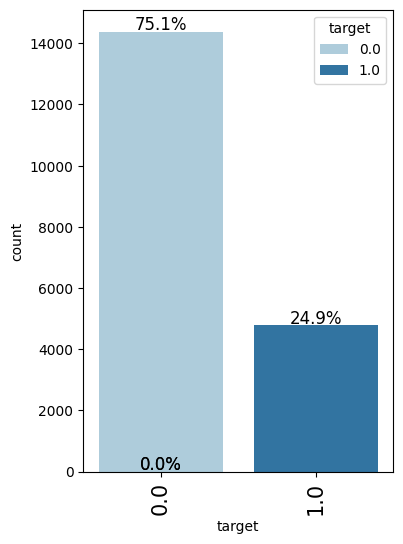

In [ ]:
plot_labeled_counts(jobs_df, "target", show_pct=True)

* The target variable is imbalanced: 75% of enrollees are not seeking a job and may simply be interested in new technologies.

#### `city_development_index`

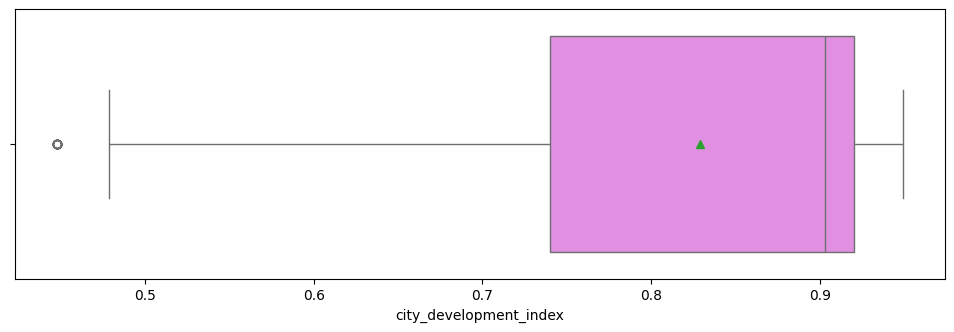

In [ ]:
plot_box_only(jobs_df, "city_development_index")

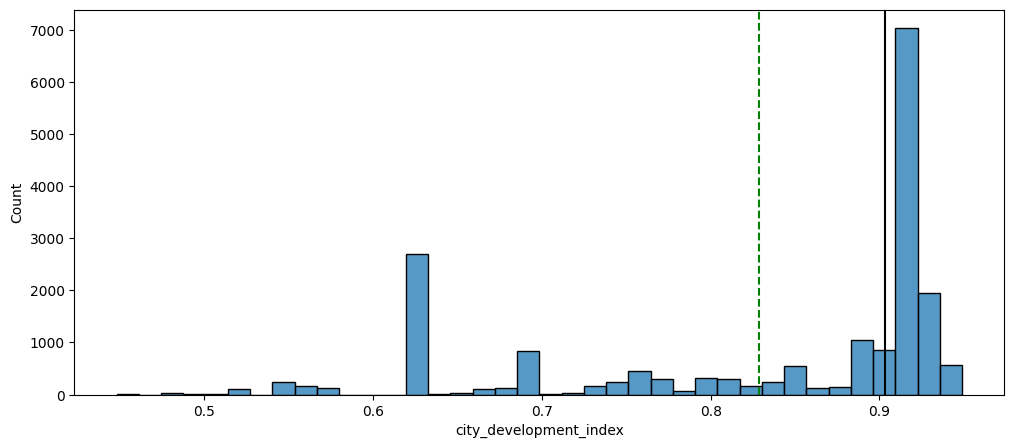

In [ ]:
plot_hist_only(jobs_df, "city_development_index")

* The distribution of city_development_index is left-skewed.
* Cities with a city_development_index below ~0.45 are outliers - such cities may be underdeveloped or tier 3 cities.
* Let's look into it further.

In [ ]:
jobs_df[jobs_df["city_development_index"] < 0.45]

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
1523,8238,city_33,0.448,NaN,Has relevent experience,Part time course,Graduate,STEM,10,50-99,NGO,>4,48,1.0
4744,30985,city_33,0.448,NaN,No relevent experience,Full time course,Graduate,STEM,2,NaN,NaN,never,43,1.0
5010,27970,city_33,0.448,Male,No relevent experience,no_enrollment,Graduate,STEM,1,NaN,NaN,never,73,1.0
5265,31194,city_33,0.448,NaN,No relevent experience,NaN,High School,NaN,5,NaN,Pvt Ltd,never,86,1.0
5567,598,city_33,0.448,NaN,Has relevent experience,Part time course,Masters,STEM,6,NaN,NaN,1,18,1.0
6127,18564,city_33,0.448,NaN,No relevent experience,Full time course,Graduate,STEM,4,NaN,Public Sector,4,32,1.0
7724,31179,city_33,0.448,Male,Has relevent experience,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,28,0.0
7864,26838,city_33,0.448,Male,Has relevent experience,no_enrollment,Graduate,STEM,8,NaN,NaN,>4,74,0.0
9134,4858,city_33,0.448,NaN,No relevent experience,Part time course,Masters,Other,2,<10,NGO,1,23,1.0
10401,19463,city_33,0.448,Male,No relevent experience,no_enrollment,Graduate,STEM,5,10000+,Pvt Ltd,2,36,0.0


* All the records with a city development index below 0.45 belong to city_33, so they appear to reflect a genuine pattern and do not need to be treated as outliers.

#### `training_hours`

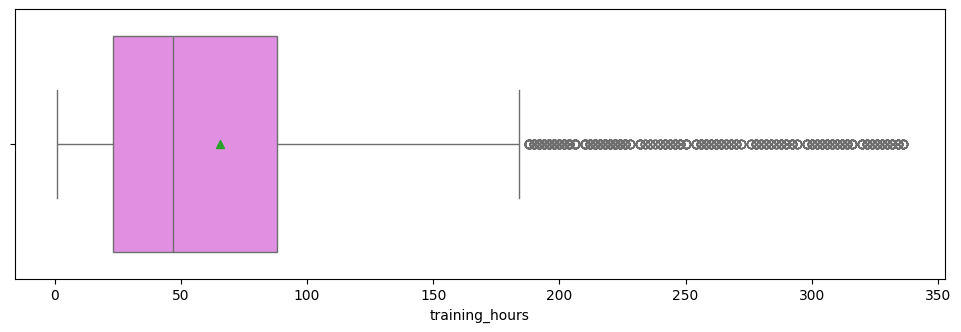

In [ ]:
plot_box_only(jobs_df, "training_hours")

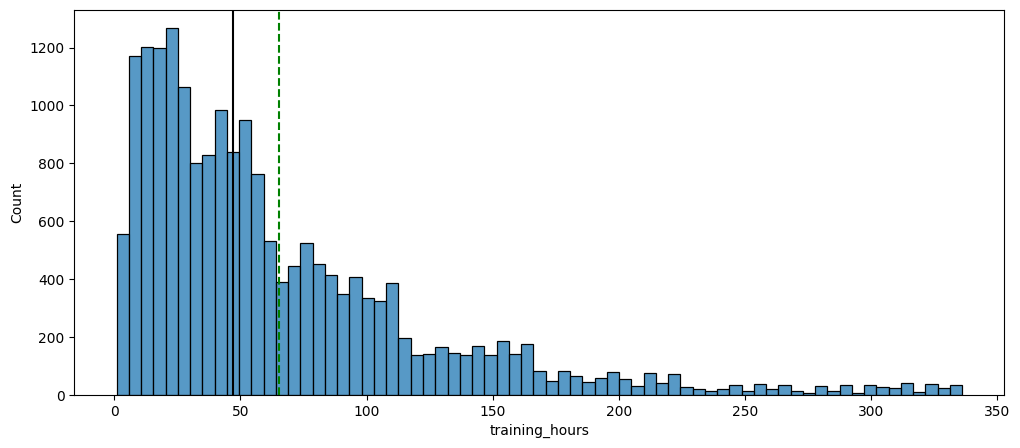

In [ ]:
plot_hist_only(jobs_df, "training_hours")

* The distribution of training_hours is right-skewed and has many outliers.
* The boxplot shows that enrollees with more than ~175hrs of training are outliers.

#### `gender`

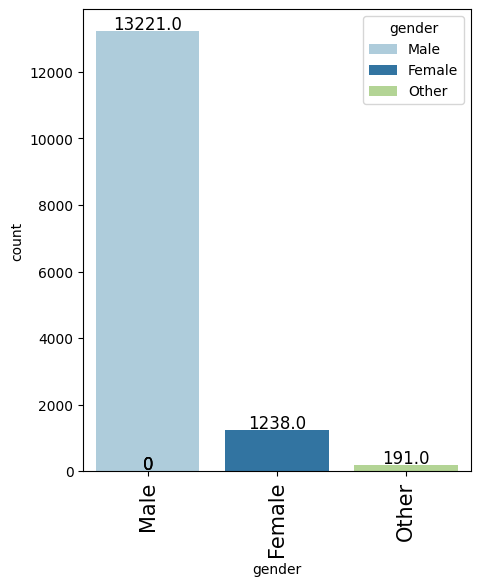

In [ ]:
plot_labeled_counts(jobs_df, "gender")

* Males make up 69% of the enrollees.

#### `relevent_experience`

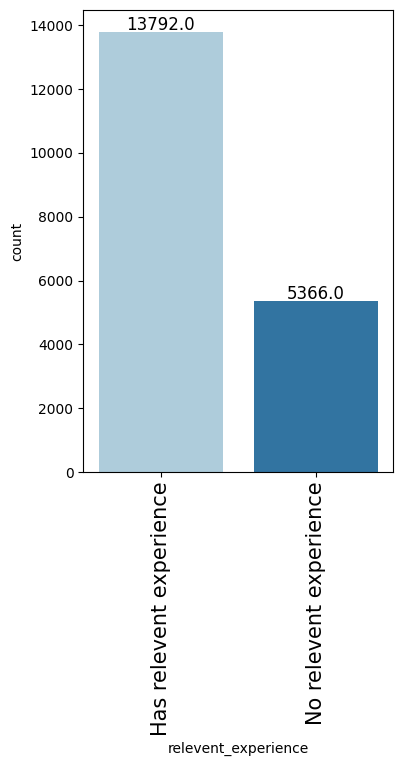

In [ ]:
plot_labeled_counts(jobs_df, "relevent_experience")

* 72% of the enrollees have some relevant experience.

#### `company_size`

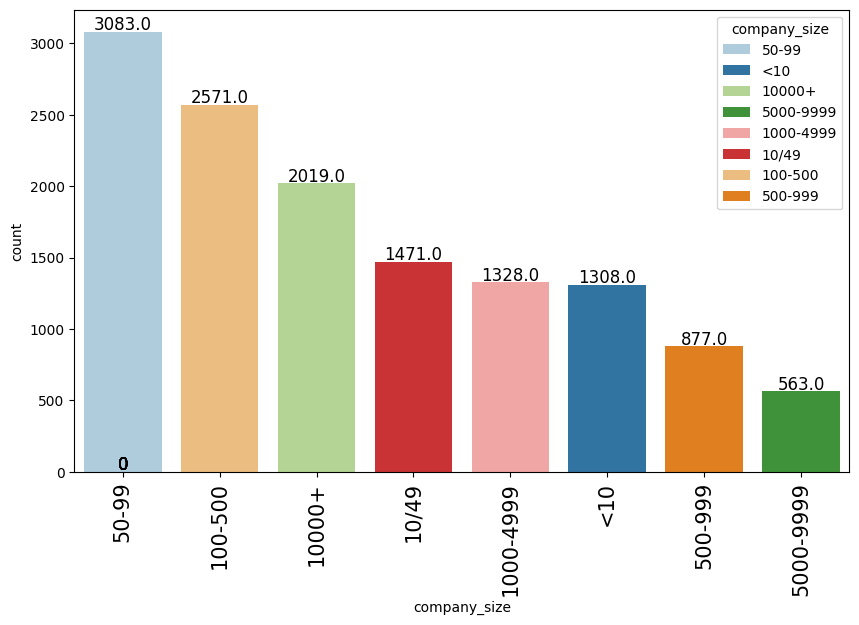

In [ ]:
plot_labeled_counts(jobs_df, "company_size")

* 16.1% of the enrollees have worked in a company with 50-99 employees, and 13.4% in a company with 100-500 employees.

### Bivariate Analysis

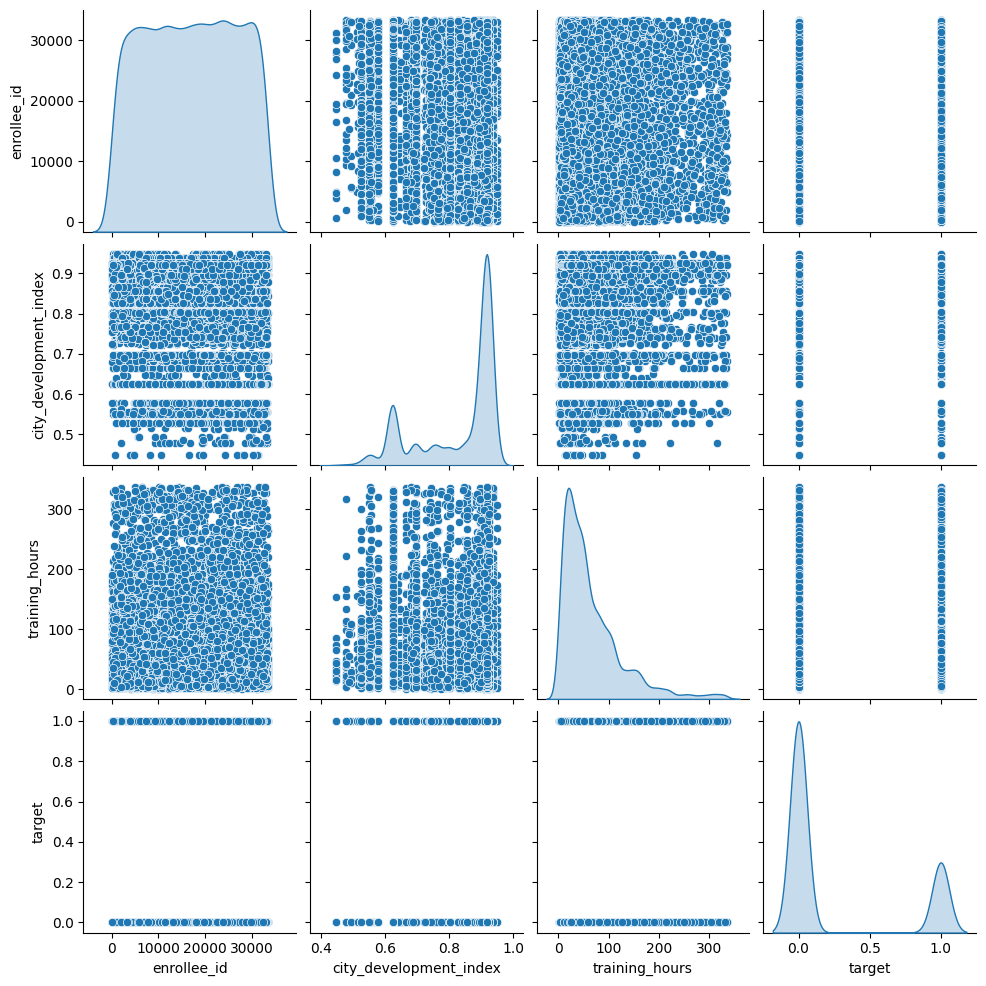

In [ ]:
sns.pairplot(data=jobs_df, diag_kind="kde")
plt.show()

* Replacing 1 and 0 with 'yes' and 'no' respectively, to make the analysis easier to read.

In [ ]:
jobs_df["target"] = jobs_df["target"].replace(1, "yes")
jobs_df["target"] = jobs_df["target"].replace(0, "no")

#### `target vs gender`

In [ ]:
show_crosstab_counts(jobs_df, "gender", "target")

target     no   yes    All
gender                    
All     11262  3388  14650
Male    10209  3012  13221
Female    912   326   1238
Other     141    50    191
------------------------------------------------------------------------------------------------------------------------


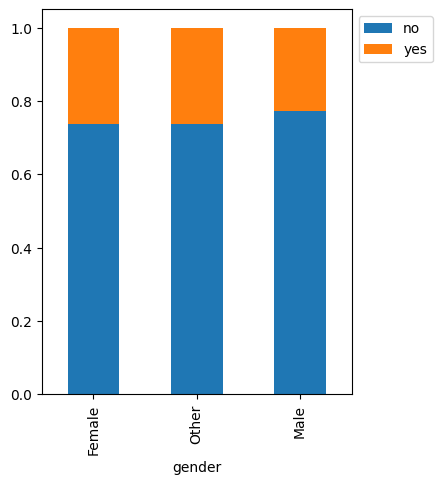

In [ ]:
plot_stacked_bars(jobs_df, "gender", "target")

* Female enrollees, followed by enrollees of other gender, are the ones most actively looking for a job change.
* Let's add 'unknown' as a category (in place of the missing values) and see whether the observations change.

In [ ]:
jobs_df["gender"] = jobs_df["gender"].replace(np.nan, "unknown")

In [ ]:
show_crosstab_counts(jobs_df, "gender", "target")

target      no   yes    All
gender                     
All      14381  4777  19158
Male     10209  3012  13221
unknown   3119  1389   4508
Female     912   326   1238
Other      141    50    191
------------------------------------------------------------------------------------------------------------------------


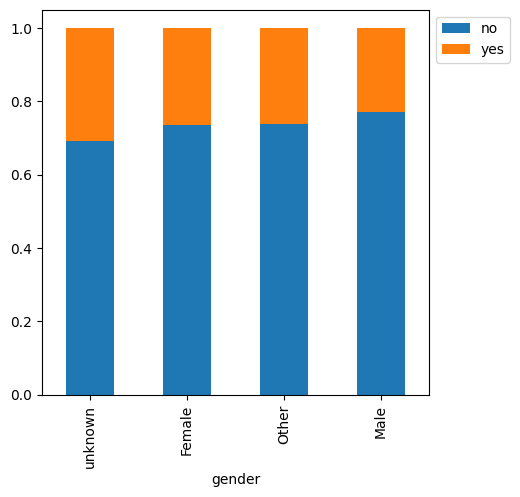

In [ ]:
plot_stacked_bars(jobs_df, "gender", "target")

* The 'unknown' gender group has the highest percentage of enrollees looking for a job change.

#### `target vs relevant_experience`

In [ ]:
show_crosstab_counts(jobs_df, "relevent_experience", "target")

target                      no   yes    All
relevent_experience                        
All                      14381  4777  19158
Has relevent experience  10831  2961  13792
No relevent experience    3550  1816   5366
------------------------------------------------------------------------------------------------------------------------


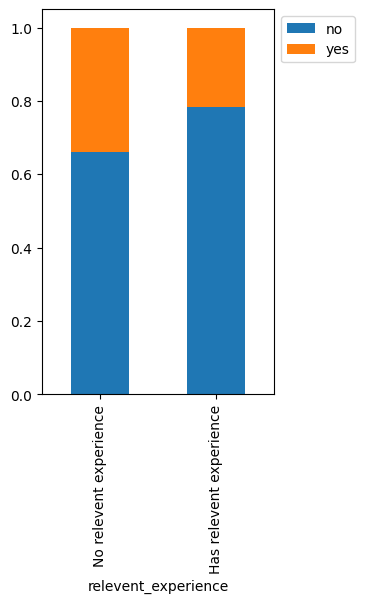

In [ ]:
plot_stacked_bars(jobs_df, "relevent_experience", "target")

* 35% of the enrollees without relevant experience are looking for a job change.
* These enrollees could be freshers in search of opportunities.
* 20% of the enrollees with relevant experience are also looking for a job change; after upskilling, they may be seeking new roles that use their newly acquired skills.

#### `target vs company_type`

In [ ]:
show_crosstab_counts(jobs_df, "company_type", "target")

target                  no   yes    All
company_type                           
All                  10625  2393  13018
Pvt Ltd               8042  1775   9817
Public Sector          745   210    955
Early Stage Startup    461   142    603
Funded Startup         861   140   1001
NGO                    424    97    521
Other                   92    29    121
------------------------------------------------------------------------------------------------------------------------


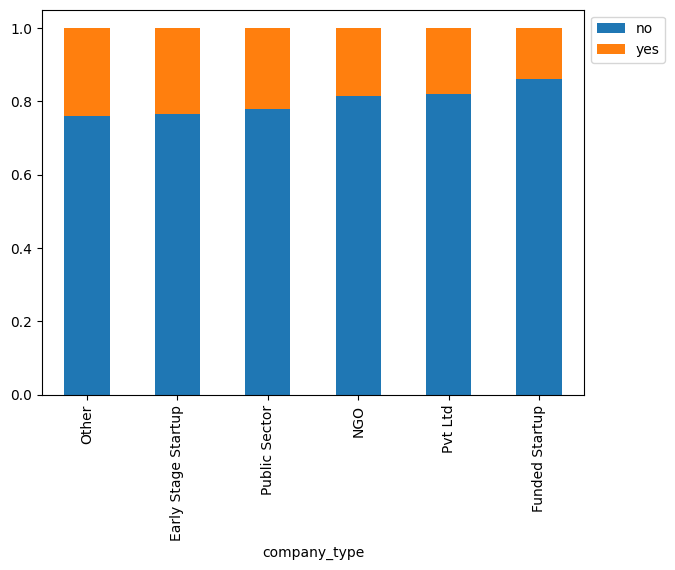

In [ ]:
plot_stacked_bars(jobs_df, "company_type", "target")

* Enrollees from funded startups show the least interest, possibly because their startup has just been funded, so they expect to grow there and only want to upskill through the training.
* Across all types of companies/sectors, ~20% of the enrollees are looking for a job change.

#### `target vs last_new_job`

In [ ]:
show_crosstab_counts(jobs_df, "last_new_job", "target")

target           no   yes    All
last_new_job                    
All           14112  4623  18735
1              5915  2125   8040
never          1713   739   2452
2              2200   700   2900
>4             2690   600   3290
3               793   231   1024
4               801   228   1029
------------------------------------------------------------------------------------------------------------------------


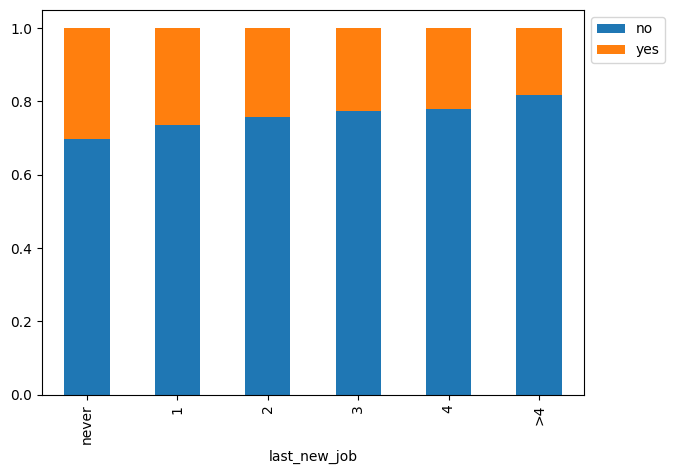

In [ ]:
plot_stacked_bars(jobs_df, "last_new_job", "target")

* Our earlier assumption that 'never' stands for freshers or people who are not currently working looks correct, as they show the most interest in a job change (looking for a start).

#### `target vs training_hours`

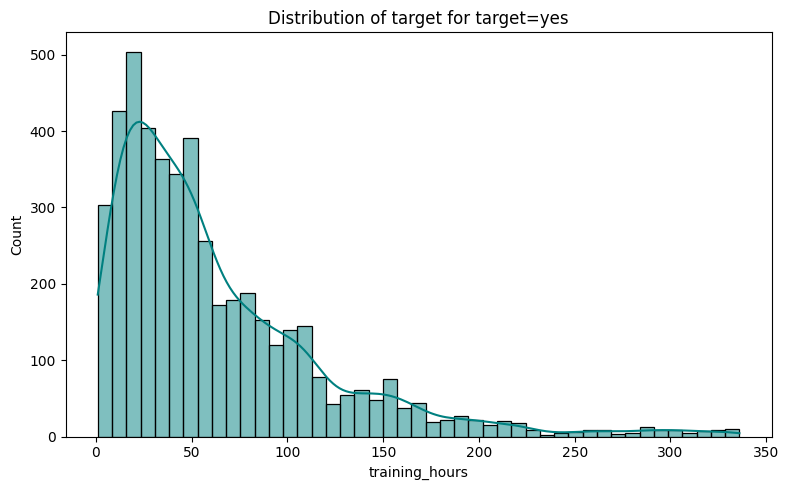

In [ ]:
plot_class_hist(jobs_df, "training_hours", "target", 0, "teal")

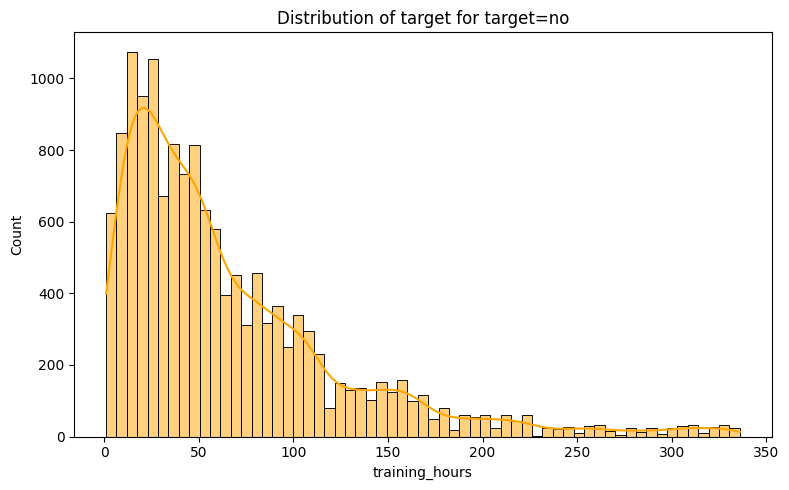

In [ ]:
plot_class_hist(jobs_df, "training_hours", "target", 1, "orange")

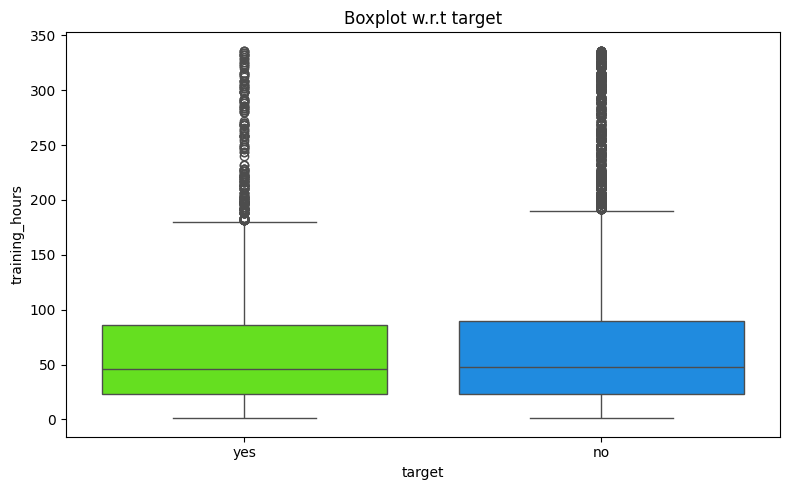

In [ ]:
plot_target_box(jobs_df, "training_hours", "target")

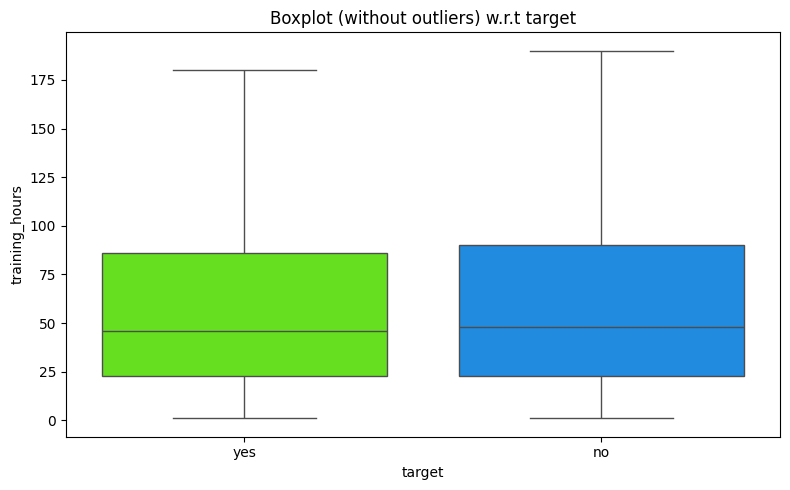

In [ ]:
plot_target_box_no_outliers(jobs_df, "training_hours", "target")

* Training hours do not appear to affect the target variable.

#### `target vs city_development_index`

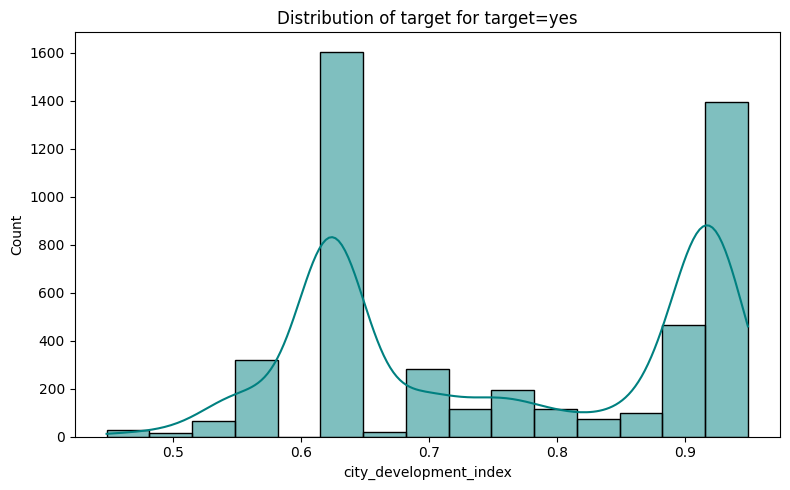

In [ ]:
plot_class_hist(jobs_df, "city_development_index", "target", 0, "teal")

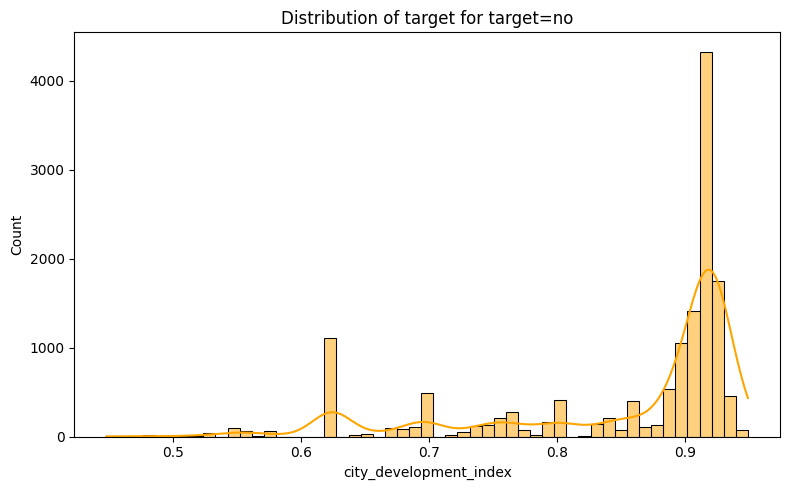

In [ ]:
plot_class_hist(jobs_df, "city_development_index", "target", 1, "orange")

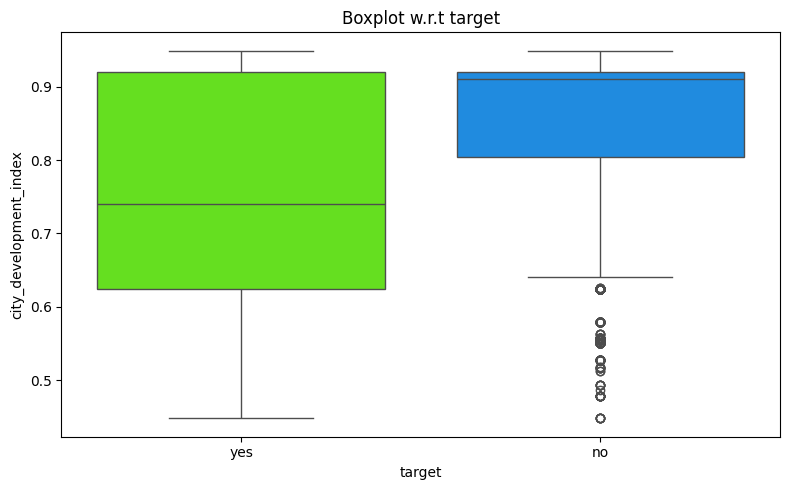

In [ ]:
plot_target_box(jobs_df, "city_development_index", "target")

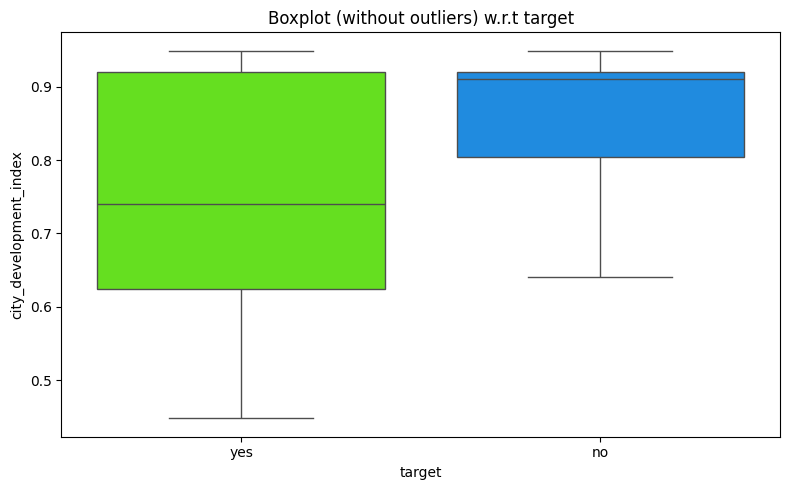

In [ ]:
plot_target_box_no_outliers(jobs_df, "city_development_index", "target")

* Enrollees looking for a job and those not looking for one differ sharply.
* An enrollee from a city with a higher development index is less likely to look for a job change than one from a city with a lower development index.
* Enrollees from cities with a low development index may be upskilling through the training in order to find better opportunities in metropolitan cities.

## <a name='link1'>Appendix: Detailed Exploratory Data Analysis (EDA)</a>

### Univariate Analysis

#### `enrolled_university`

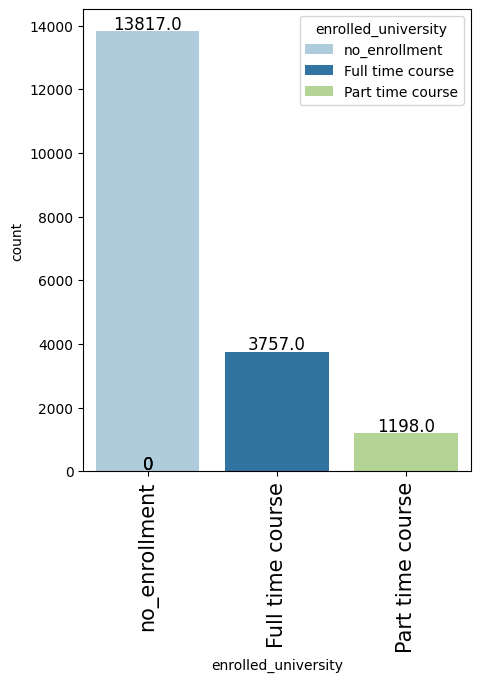

In [ ]:
plot_labeled_counts(jobs_df, "enrolled_university")

* 72.1% of the enrollees were not enrolled in any university, followed by 19.6% who were on a full-time course.

#### `education_level`

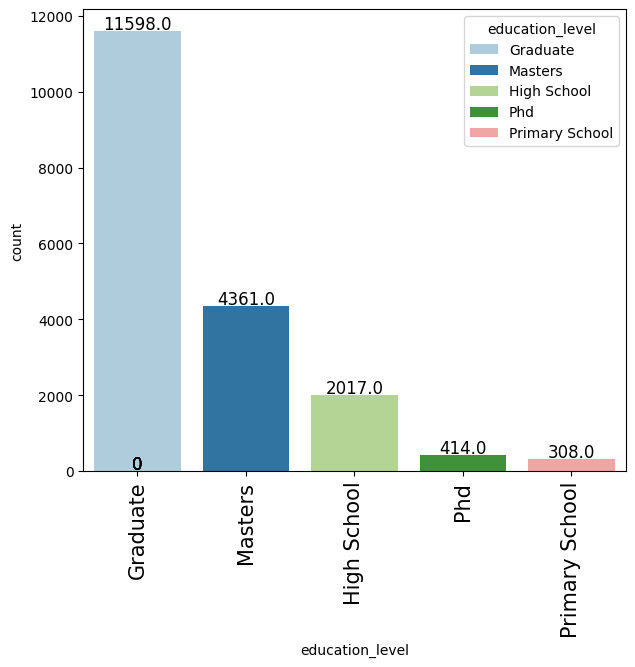

In [ ]:
plot_labeled_counts(jobs_df, "education_level")

* Graduates make up 60.5% of the enrollees, followed by 22.8% who hold a Masters degree.

#### `major_discipline`

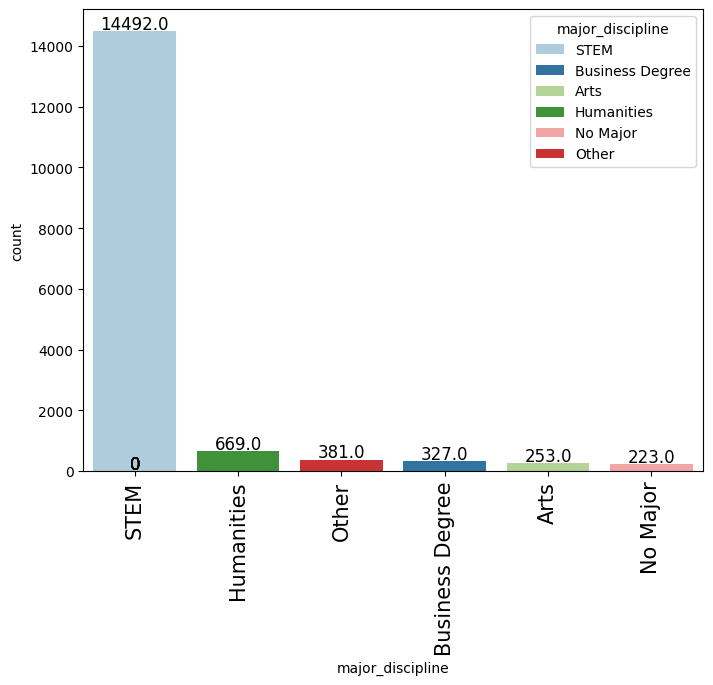

In [ ]:
plot_labeled_counts(jobs_df, "major_discipline")

* STEM is the major discipline of 75.5% of the enrollees. STEM covers programs in science, technology, engineering, and mathematics.

#### `company_type`

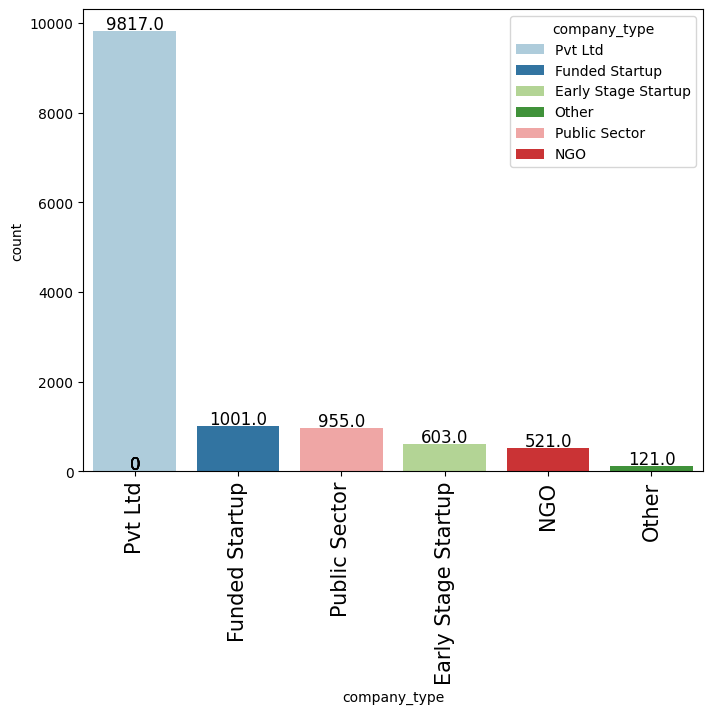

In [ ]:
plot_labeled_counts(jobs_df, "company_type")

* 51.2% of the enrollees have worked in private companies, followed by 8.3% in startups.

#### `last_new_job`

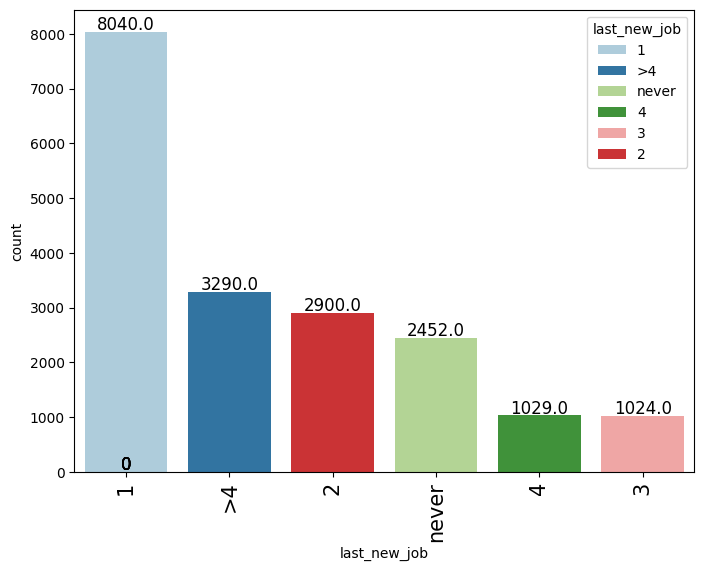

In [ ]:
plot_labeled_counts(jobs_df, "last_new_job")

* 42% of the enrollees have a gap of 1 year between their current and previous job, followed by 17.2% with a gap of more than 4 years.
* 'Never' here can mean that the enrollee has never worked before (freshers) or is not working at the moment.

### Bivariate analysis

#### Correlation Check

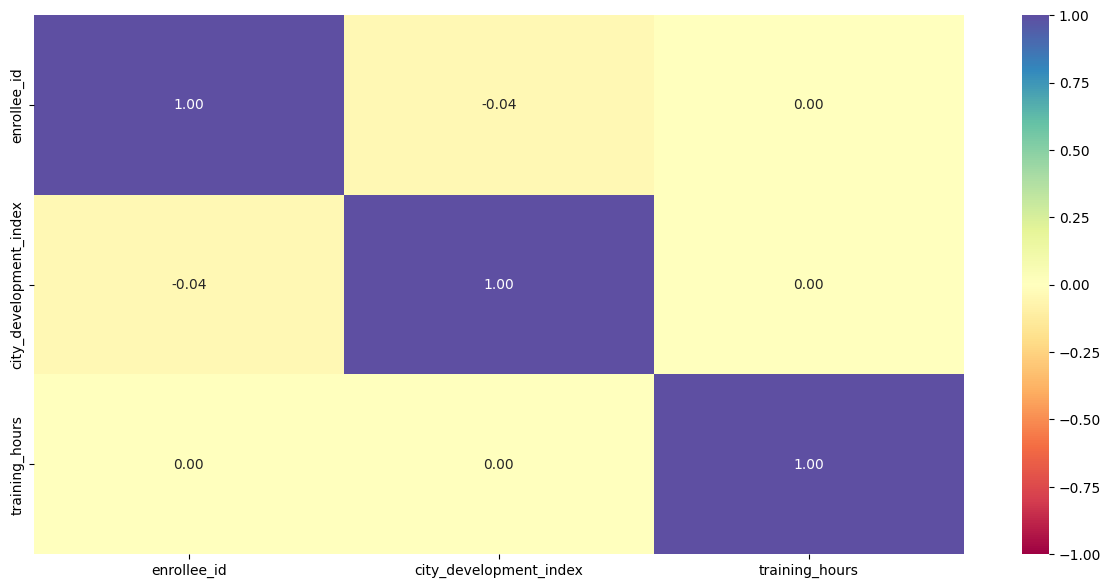

In [ ]:
plt.figure(figsize=(15, 7))
sns.heatmap(
    jobs_df.corr(numeric_only=True),
    annot=True,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    cmap="Spectral",
)
plt.show()

* No strong correlation exists with the target or between any of the independent variables.
* City development index is negatively related to the target.

#### `target vs city`

In [ ]:
show_crosstab_counts(jobs_df, "city", "target")

target       no   yes    All
city                        
All       14381  4777  19158
city_21    1105  1597   2702
city_103   3427   928   4355
city_160    646   199    845
city_16    1354   179   1533
...         ...   ...    ...
city_2        7     0      7
city_39      11     0     11
city_62       5     0      5
city_8        4     0      4
city_82       4     0      4

[124 rows x 3 columns]
------------------------------------------------------------------------------------------------------------------------


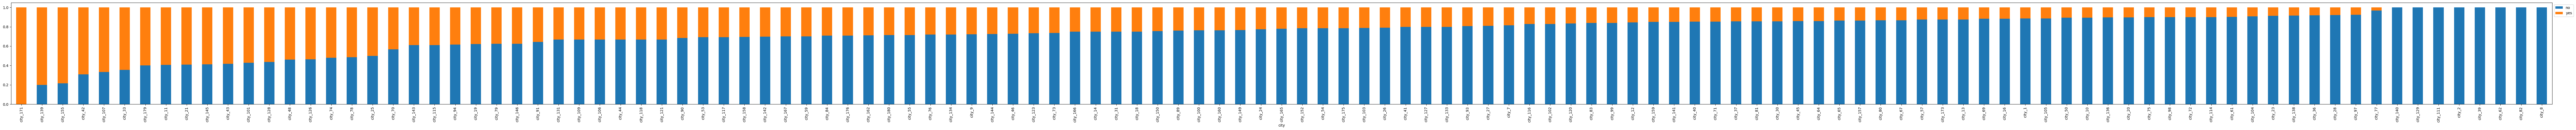

In [ ]:
plot_stacked_bars(jobs_df, "city", "target")


* The cities with the highest percentage of enrollees looking for a job are probably tier 2 or tier 3 cities, where people seek better opportunities.
* This column clearly separates enrollees looking for a job from those who are not, so it can serve as an important predictor.

#### `target vs major_discipline`

In [ ]:
show_crosstab_counts(jobs_df, "major_discipline", "target")

target               no   yes    All
major_discipline                    
All               12117  4228  16345
STEM              10701  3791  14492
Humanities          528   141    669
Other               279   102    381
Business Degree     241    86    327
No Major            168    55    223
Arts                200    53    253
------------------------------------------------------------------------------------------------------------------------


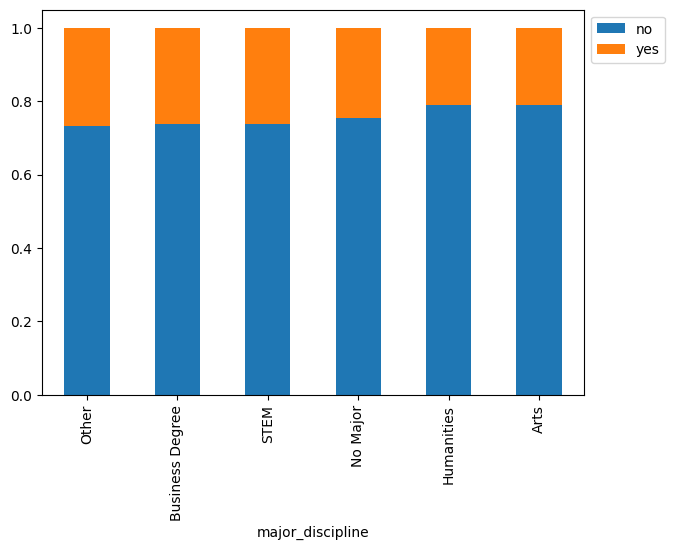

In [ ]:
plot_stacked_bars(jobs_df, "major_discipline", "target")

* A high proportion of enrollees are looking for a job change in every category.

#### `target vs experience`

In [ ]:
show_crosstab_counts(jobs_df, "experience", "target")

target         no   yes    All
experience                    
All         14339  4754  19093
>20          2783   503   3286
3             876   478   1354
4             946   457   1403
5            1018   412   1430
2             753   374   1127
6             873   343   1216
7             725   303   1028
<1            285   237    522
1             316   233    549
9             767   213    980
10            778   207    985
8             607   195    802
11            513   151    664
15            572   114    686
14            479   107    586
12            402    92    494
13            322    77    399
16            436    72    508
17            285    57    342
19            251    53    304
18            237    43    280
20            115    33    148
------------------------------------------------------------------------------------------------------------------------


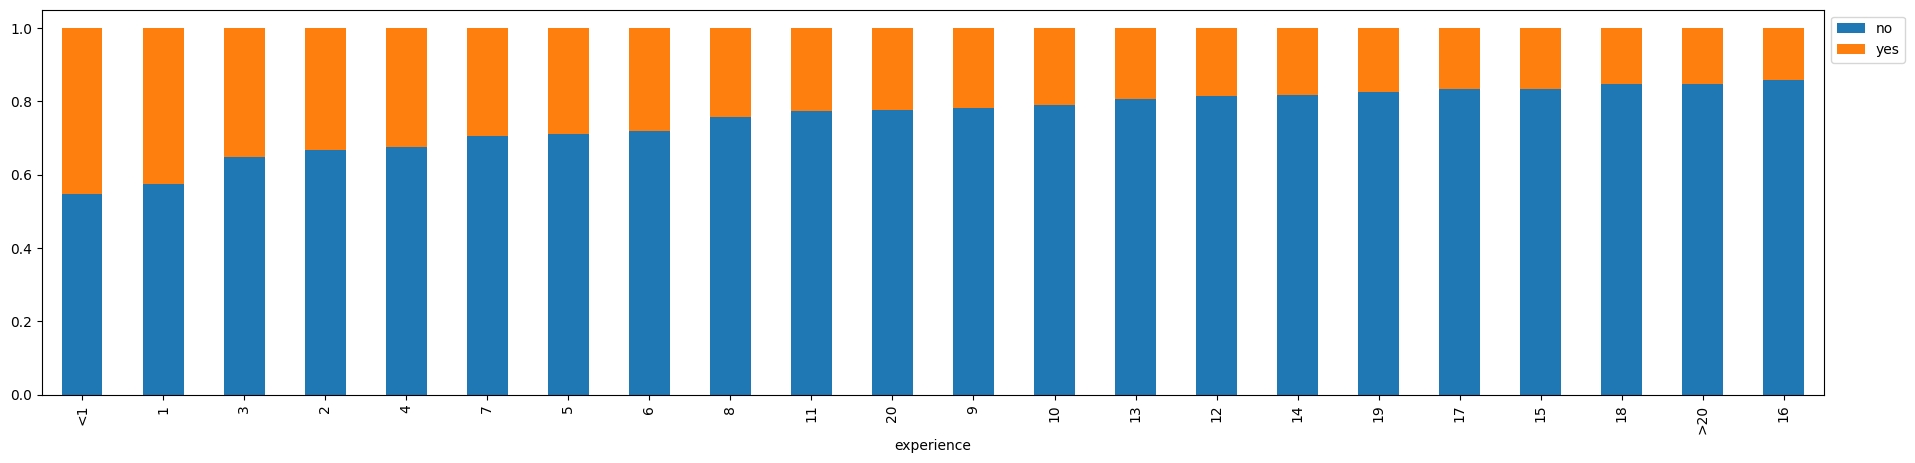

In [ ]:
plot_stacked_bars(jobs_df, "experience", "target")

* A high proportion of the enrollees looking for a job change have less than 10 years of experience.
* Those with <1 year are likely freshers who want to start a job in a relevant field after the training.

#### `target vs company_size`

In [ ]:
show_crosstab_counts(jobs_df, "company_size", "target")

target           no   yes    All
company_size                    
All           10853  2367  13220
50-99          2538   545   3083
100-500        2156   415   2571
10000+         1634   385   2019
10/49          1127   344   1471
<10            1084   224   1308
1000-4999      1128   200   1328
500-999         725   152    877
5000-9999       461   102    563
------------------------------------------------------------------------------------------------------------------------


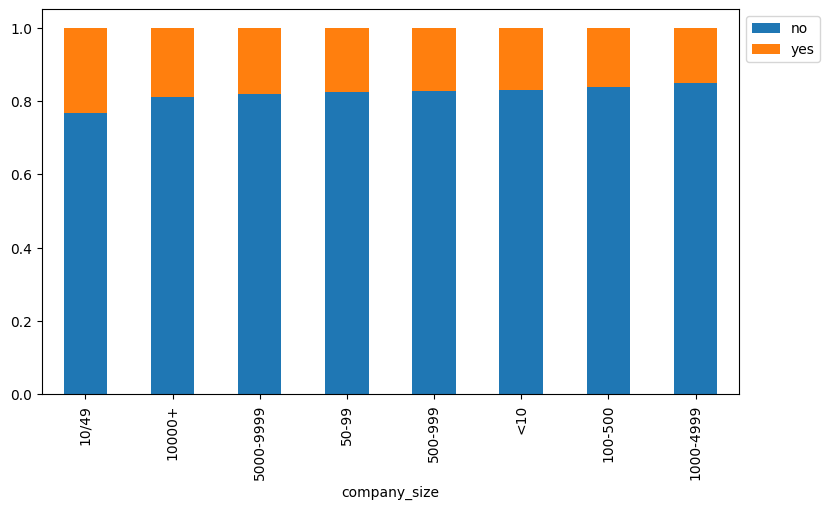

In [ ]:
plot_stacked_bars(jobs_df, "company_size", "target")

* Around 20% of the enrollees, whatever the size of their company, are looking for a job change.

#### `target vs enrolled_university`

In [ ]:
show_crosstab_counts(jobs_df, "enrolled_university", "target")

target                  no   yes    All
enrolled_university                    
All                  14118  4654  18772
no_enrollment        10896  2921  13817
Full time course      2326  1431   3757
Part time course       896   302   1198
------------------------------------------------------------------------------------------------------------------------


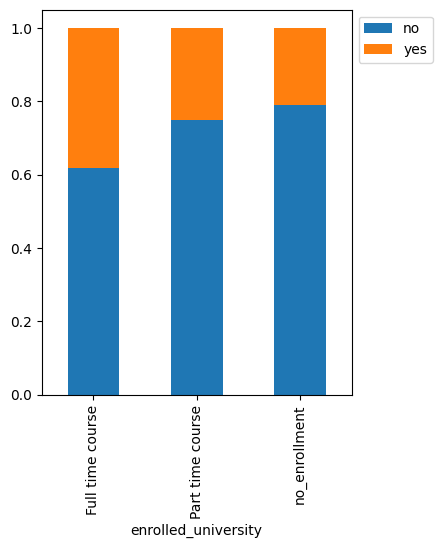

In [ ]:
plot_stacked_bars(jobs_df, "enrolled_university", "target")

* A high portion of enrollees are looking for a job change in all three categories.
* ~40% of the enrollees on full-time courses are looking for a job change.
* ~30% of the enrollees on part-time courses are looking for a job change.

#### `target vs education_level`

In [ ]:
show_crosstab_counts(jobs_df, "education_level", "target")

target              no   yes    All
education_level                    
All              14025  4673  18698
Graduate          8353  3245  11598
Masters           3426   935   4361
High School       1623   394   2017
Phd                356    58    414
Primary School     267    41    308
------------------------------------------------------------------------------------------------------------------------


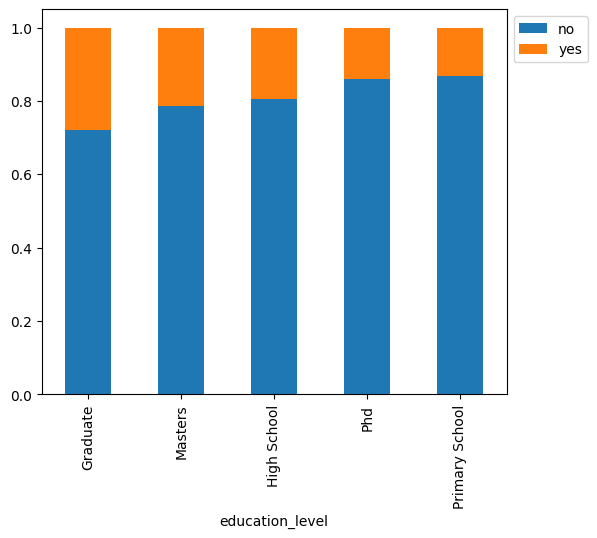

In [ ]:
plot_stacked_bars(jobs_df, "education_level", "target")

* A high proportion of enrollees are looking for a job change among Graduates, Masters, and High Schoolers.
* ~30% of the graduate enrollees are looking for a job change.
* 20% of the enrollees with a master's degree are looking for a job change.

### To jump back to the EDA summary section, click <a href = #link2>here</a>.

## Data Preprocessing

* `enrollee_id:` Being a unique identifier, enrollee_id adds nothing to the analysis and can be dropped.

In [ ]:
# enrollee_id is different for every candidate, so it likely adds nothing to the model
jobs_df.drop(["enrollee_id"], axis=1, inplace=True)

### Encoding categorical variables

In [ ]:
jobs_df["city"].nunique()

123

* The data has 123 unique cities; the number of levels can be reduced by grouping them into 3 major categories:
  * Developed city - city development index greater than 0.90
  * Developing city - city development index between 0.74 and 0.90
  * Under-Developed city - city development index between 0.4 and 0.74

In [ ]:
jobs_df["city_development_index"].describe()

,city_development_index
count,19158.000000
mean,0.828848
std,0.123362
min,0.448000
25%,0.740000
50%,0.903000
75%,0.920000
max,0.949000


In [ ]:
# bucketing the variable into groups based on quantiles
jobs_df["city"] = pd.qcut(
    jobs_df["city_development_index"],
    q=[0, 0.25, 0.5, 1],
    labels=["Under_Developed", "Developing", "Developed"],
)

In [ ]:
jobs_df["city"].value_counts()

,count
city,
Developed,9561
Under_Developed,4838
Developing,4759


* The 123 unique values have been grouped into 3 categories.

In [ ]:
jobs_work = jobs_df.copy()

In [ ]:
jobs_work.head()

,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,Developed,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,yes
1,Developing,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,no
2,Under_Developed,0.624,unknown,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,no
3,Developing,0.789,unknown,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,yes
4,Developing,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,no


- Missing values will be imputed after splitting the data into train, test and validation sets, to avoid data leakage

### Data Preparation for Modeling

In [ ]:
feat = jobs_work.drop(["target"], axis=1)
label = jobs_work["target"].apply(lambda v: 1 if v == "yes" else 0)

- By default, `pandas` treats missing values as either float ('nan') or 'unknown' data type.
- We'll convert them to `pd.NA`, the `pandas` data type for NaN.

In [ ]:
# converting missing values to pandas NaN
feat.fillna(pd.NA, inplace=True)

# converting the value "unknown" to pandas NaN
feat.replace(to_replace="unknown", value=pd.NA, inplace=True)

In [ ]:
# Dividing the data into training, validation and test sets:
# step 1: separate the data into a temporary set and a test set

X_rest, X_te, y_rest, y_te = train_test_split(
    feat, label, test_size=0.2, random_state=1, stratify=label
)

# step 2: break the temporary set into training and validation sets

X_tr, X_valid, y_tr, y_valid = train_test_split(
    X_rest, y_rest, test_size=0.25, random_state=1, stratify=y_rest
)
print(X_tr.shape, X_valid.shape, X_te.shape)

(11494, 12) (3832, 12) (3832, 12)


In [ ]:
print("Number of rows in train data =", X_tr.shape[0])
print("Number of rows in validation data =", X_valid.shape[0])
print("Number of rows in test data =", X_te.shape[0])

Number of rows in train data = 11494
Number of rows in validation data = 3832
Number of rows in test data = 3832


- We'll store the indices of the train, validation, and test for later use.

In [ ]:
train_idx = set(X_tr.index)
valid_idx = set(X_valid.index)
test_idx = set(X_te.index)

### Missing Value Treatment

In [ ]:
X_tr.isnull().sum()

,0
city,0
city_development_index,0
gender,2664
relevent_experience,0
enrolled_university,217
education_level,272
major_discipline,1677
experience,42
company_size,3566
company_type,3682


In [ ]:
X_valid.isnull().sum()

,0
city,0
city_development_index,0
gender,917
relevent_experience,0
enrolled_university,85
education_level,99
major_discipline,567
experience,13
company_size,1178
company_type,1223


In [ ]:
X_te.isnull().sum()

,0
city,0
city_development_index,0
gender,927
relevent_experience,0
enrolled_university,84
education_level,89
major_discipline,569
experience,10
company_size,1194
company_type,1235


* Missing values are present in the columns ***gender, enrolled_university , education_level , major_discipline, experience , company_size , company_type*** , and **last_new_job**.

* All of them are categorical variables, so a suitable statistic must be chosen for imputation.

* The mode is the most suitable statistic.
    * It works well for categorical variables because it fills missing values with the most frequent category, so the imputed values represent the typical or most likely category in the dataset.

In [ ]:
# setting up sklearn's SimpleImputer to fill missing values with the mode (the most frequent value)
mode_imputer = SimpleImputer(missing_values=pd.NA, strategy="most_frequent")

- To avoid data leakage, the value used for imputation is computed from the training set and then reused to fill the missing values in the validation and test sets.
- `fit_transform()` is used to compute the imputation value and fill the missing values.
- `transform()` is used to only fill the missing values.

In [ ]:
# apply fit() and transform() to the training set
X_tr[:] = mode_imputer.fit_transform(X_tr[:])

# apply only transform() to the validation and test sets
X_valid[:] = mode_imputer.transform(X_valid[:])
X_te[:] = mode_imputer.transform(X_te[:])

### Creating Dummy Variables

In [ ]:
# stacking X_tr, X_valid and X_te row-wise
encoded_df = pd.concat([X_tr, X_valid, X_te])

In [ ]:
# one-hot encoding the categorical variables
encoded_df = pd.get_dummies(encoded_df, drop_first=True, dtype=int)
print(encoded_df.shape)

(19158, 56)


* The data has 56 columns after encoding.

* The indices of the train, validation, and test sets were stored earlier.

* These indices can now be used to pull the corresponding subsets out of `final_df`.

In [ ]:
X_tr = encoded_df.loc[list(train_idx)]

X_valid = encoded_df.loc[list(valid_idx)]

X_te = encoded_df.loc[list(test_idx)]

##Model Building

### Model evaluation criterion

**Model can make wrong predictions as:**
1. Predicting an enrollee is looking for a job change but in reality, the enrollee is not looking for a change - Loss of resources
2. Predicting an enrollee is not looking for a job change but the enrollee is looking for a job change  - Loss of opportunity

**Which case is more important?**
* Predicting an enrollee is not looking for a job change but the enrollee is looking for a job change i.e. losing on a potential candidate as the candidate will not be targeted by the HR team when he should be targeted.

**How to reduce this loss i.e need to reduce False Negatives?**
* Company would want Recall to be maximized, greater the Recall lesser the chances of false negatives.

In [ ]:
# function that calculates several metrics to judge a classification model built with sklearn
def evaluate_classifier(clf, X_in, y_true):
    """
    Computes various metrics to evaluate the performance of a classifier

    clf: the classifier
    X_in: the independent variables
    y_true: the dependent variable
    """

    # generating predictions from the independent variables
    y_hat = clf.predict(X_in)

    accuracy = accuracy_score(y_true, y_hat)  # calculating accuracy
    rec = recall_score(y_true, y_hat)  # calculating recall
    prec = precision_score(y_true, y_hat)  # calculating precision
    f1_val = f1_score(y_true, y_hat)  # calculating the F1-score

    # putting the metrics into a dataframe
    metrics_df = pd.DataFrame(
        {"Accuracy": accuracy, "Recall": rec, "Precision": prec, "F1": f1_val},
        index=[0],
    )

    return metrics_df

In [ ]:
def draw_confusion_matrix(clf, X_in, y_true):
    """
    Plots the confusion matrix along with percentages

    clf: the classifier
    X_in: the independent variables
    y_true: the dependent variable
    """
    y_hat = clf.predict(X_in)
    conf_mat = confusion_matrix(y_true, y_hat)
    cell_labels = np.asarray(
        [
            ["{0:0.0f}".format(val) + "\n{0:.2%}".format(val / conf_mat.flatten().sum())]
            for val in conf_mat.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(conf_mat, annot=cell_labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

### Model building with original data

In [ ]:
base_lr = LogisticRegression(random_state=1)
base_lr.fit(X_tr, y_tr)

LogisticRegression(random_state=1)

In [ ]:
# computing the metrics on the training set
base_train_metrics = evaluate_classifier(
    base_lr, X_tr, y_tr
)
print("Training performance:")
base_train_metrics

Training performance:


,Accuracy,Recall,Precision,F1
0,0.750653,0.0,0.0,0.0


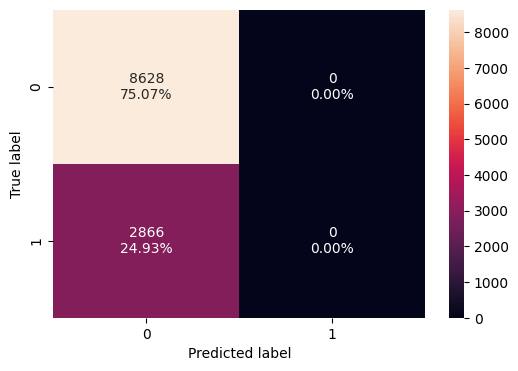

In [ ]:
# plotting the confusion matrix
draw_confusion_matrix(base_lr, X_tr, y_tr)

In [ ]:
# computing the metrics on the validation set
base_val_metrics = evaluate_classifier(base_lr, X_valid, y_valid)
print("Validation performance:")
base_val_metrics

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.750522,0.0,0.0,0.0


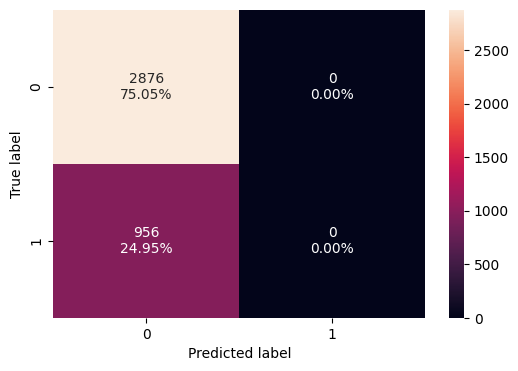

In [ ]:
# plotting the confusion matrix
draw_confusion_matrix(base_lr, X_valid, y_valid)

- The model predicts 0 for every input.
* As a result, precision, recall, and f1_score are all 0.
- Let's find out why this happens

In [ ]:
y_tr.value_counts()

,count
target,
0,8628
1,2866


* `y_train` is highly imbalanced, with 75% of the values being 0 and the rest 1.
   - We saw earlier that the target variable `y` is imbalanced in the same ratio.

* Since the recall is zero, let's try oversampling (increasing the training data) to see whether the model performance improves.

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

- `Stratified K-fold` is a variation of KFold that returns stratified folds. The folds are made by preserving the percentage of samples for each class.

In [ ]:
eval_metric = "recall"
cv_splitter = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # using 5 splits
cv_recall_base = cross_val_score(
    estimator=base_lr, X=X_tr, y=y_tr, scoring=eval_metric, cv=cv_splitter
)
cv_recall_base

array([0., 0., 0., 0., 0.])

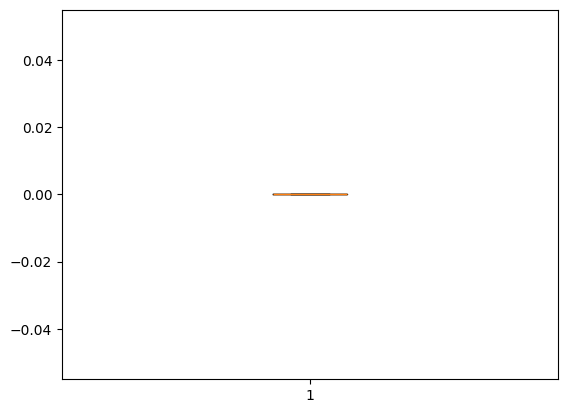

In [ ]:
# boxplot of the cross-validation scores for the model above
plt.boxplot(cv_recall_base)
plt.show()

* The cross-validation performance on the training set is zero.

### Model Building with oversampled data

In [ ]:
print("Before Oversampling, counts of label 'Yes': {}".format(sum(y_tr == 1)))
print("Before Oversampling, counts of label 'No': {} \n".format(sum(y_tr == 0)))

smote = SMOTE(
    sampling_strategy=1, k_neighbors=5, random_state=1
)  # SMOTE: Synthetic Minority Over-sampling Technique
X_tr_smote, y_tr_smote = smote.fit_resample(X_tr, y_tr)


print("After Oversampling, counts of label 'Yes': {}".format(sum(y_tr_smote == 1)))
print("After Oversampling, counts of label 'No': {} \n".format(sum(y_tr_smote == 0)))


print("After Oversampling, the shape of train_X: {}".format(X_tr_smote.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_tr_smote.shape))

Before Oversampling, counts of label 'Yes': 2866
Before Oversampling, counts of label 'No': 8628 

After Oversampling, counts of label 'Yes': 8628
After Oversampling, counts of label 'No': 8628 

After Oversampling, the shape of train_X: (17256, 56)
After Oversampling, the shape of train_y: (17256,) 



In [ ]:
lr_smote = LogisticRegression(random_state=1)

# Training the basic logistic regression model with training set
lr_smote.fit(X_tr_smote, y_tr_smote)

LogisticRegression(random_state=1)

In [ ]:
# computing the metrics on the training set
smote_train_metrics = evaluate_classifier(
    lr_smote, X_tr_smote, y_tr_smote
)
print("Training performance:")
smote_train_metrics

Training performance:


,Accuracy,Recall,Precision,F1
0,0.767096,0.677214,0.825632,0.744094


In [ ]:
# computing the metrics on the validation set
smote_val_metrics = evaluate_classifier(
    lr_smote, X_valid, y_valid
)
print("validation performance:")
smote_val_metrics

validation performance:


,Accuracy,Recall,Precision,F1
0,0.679019,0.148536,0.25448,0.187583


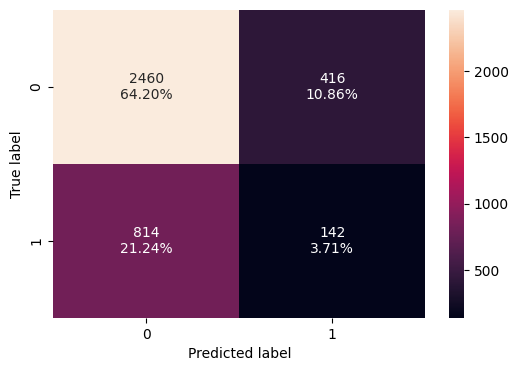

In [ ]:
# plotting the confusion matrix
draw_confusion_matrix(lr_smote, X_valid, y_valid)

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

In [ ]:
eval_metric = "recall"
cv_splitter = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # using 5 splits
cv_recall_smote = cross_val_score(
    estimator=lr_smote, X=X_tr_smote, y=y_tr_smote, scoring=eval_metric, cv=cv_splitter
)
cv_recall_smote

array([0.67265353, 0.66898551, 0.67942029, 0.67902665, 0.65932793])

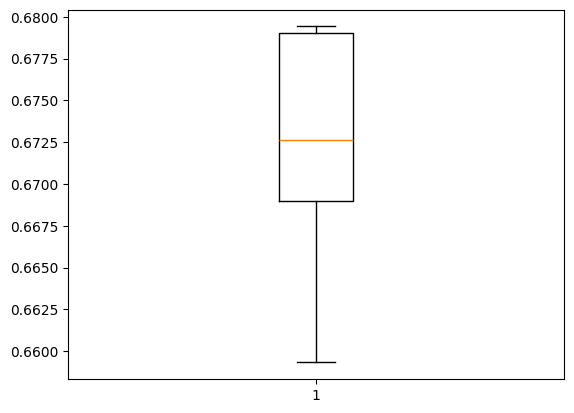

In [ ]:
# boxplot of the cross-validation scores for the model above
plt.boxplot(cv_recall_smote)
plt.show()

* Recall of the model on the training set lies between 0.63 and 0.64, an improvement over the model built on the original dataset


* Performance improved on the training set, but the model cannot reproduce it on the validation set, which points to overfitting
* Let's try regularization to see whether the overfitting can be reduced



### Regularization

In [ ]:
# select the type of classifier
lr_tuned = LogisticRegression(random_state=1, solver="saga")

# Grid of param_grid to choose from
param_grid = {"C": np.arange(0.1, 1.1, 0.1)}

# performing the grid search
grid_search = GridSearchCV(lr_tuned, param_grid, scoring="recall")
grid_search = grid_search.fit(X_tr_smote, y_tr_smote)

# Set the clf to the best combination of param_grid
lr_tuned = grid_search.best_estimator_

# train the best estimator on the data
lr_tuned.fit(X_tr_smote, y_tr_smote)

LogisticRegression(C=np.float64(0.1), random_state=1, solver='saga')

In [ ]:
# computing the metrics on the training set
tuned_train_metrics = evaluate_classifier(
    lr_tuned, X_tr_smote, y_tr_smote
)
print("Training performance:")
tuned_train_metrics

Training performance:


,Accuracy,Recall,Precision,F1
0,0.700452,0.658554,0.718786,0.687353


In [ ]:
# computing the metrics on the validation set
tuned_val_metrics = evaluate_classifier(
    lr_tuned, X_valid, y_valid
)
print("Validation performance:")
tuned_val_metrics

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.63309,0.278243,0.270876,0.27451


* Regularization has reduced the overfitting to some extent, but the model is still not useful.

### Model Building with undersampled data

In [ ]:
under_sampler = RandomUnderSampler(random_state=1, sampling_strategy=1)
X_tr_rus, y_tr_rus = under_sampler.fit_resample(X_tr, y_tr)


print("Before UnderSampling, counts of label '1': {}".format(sum(y_tr == 1)))
print("Before UnderSampling, counts of label '0': {} \n".format(sum(y_tr == 0)))


print("After UnderSampling, counts of label '1': {}".format(sum(y_tr_rus == 1)))
print("After UnderSampling, counts of label '0': {} \n".format(sum(y_tr_rus == 0)))


print("After UnderSampling, the shape of train_X: {}".format(X_tr_rus.shape))
print("After UnderSampling, the shape of train_y: {} \n".format(y_tr_rus.shape))

Before UnderSampling, counts of label '1': 2866
Before UnderSampling, counts of label '0': 8628 

After UnderSampling, counts of label '1': 2866
After UnderSampling, counts of label '0': 2866 

After UnderSampling, the shape of train_X: (5732, 56)
After UnderSampling, the shape of train_y: (5732,) 



In [ ]:
lr_rus = LogisticRegression(random_state=1)
lr_rus.fit(X_tr_rus, y_tr_rus)

LogisticRegression(random_state=1)

In [ ]:
# computing the metrics on the training set
rus_train_metrics = evaluate_classifier(
    lr_rus, X_tr_rus, y_tr_rus
)
print("Training performance:")
rus_train_metrics

Training performance:


,Accuracy,Recall,Precision,F1
0,0.533147,0.523378,0.533808,0.528541


In [ ]:
# computing the metrics on the validation set
rus_val_metrics = evaluate_classifier(
    lr_rus, X_valid, y_valid
)
print("Validation performance:")
rus_val_metrics

Validation performance:


,Accuracy,Recall,Precision,F1
0,0.517223,0.529289,0.265477,0.353599


* The model performs similarly on the training and validation sets, so it generalizes well

**Let's evaluate the model performance by using KFold and cross_val_score**

- `K-Folds cross-validation` provides dataset indices to split data into train/validation sets. Split dataset into k consecutive stratified folds (without shuffling by default). Each fold is then used once as validation while the k - 1 remaining folds form the training set.

In [ ]:
eval_metric = "recall"
cv_splitter = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=1
)  # using 5 splits
cv_recall_rus = cross_val_score(
    estimator=lr_rus, X=X_tr_rus, y=y_tr_rus, scoring=eval_metric, cv=cv_splitter
)
cv_recall_rus

array([0.5008726 , 0.46689895, 0.504363  , 0.52181501, 0.51832461])

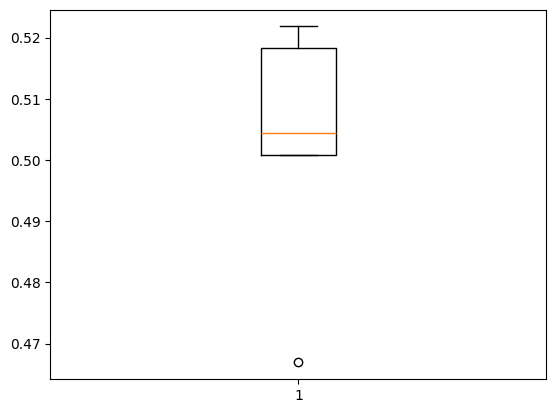

In [ ]:
# boxplot of the cross-validation scores for the model above
plt.boxplot(cv_recall_rus)
plt.show()

* Recall of the model on the training set lies between 0.5 and 0.52, an improvement over the initial model (without oversampling)

## Model Performance Comparison and Final Model Selection

In [ ]:
# comparing performance on the training set

train_comparison_df = pd.concat(
    [
        base_train_metrics.T,
        smote_train_metrics.T,
        tuned_train_metrics.T,
        rus_train_metrics.T,
    ],
    axis=1,
)
train_comparison_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Training performance comparison:")
train_comparison_df

Training performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.750653,0.767096,0.700452,0.533147
Recall,0.000000,0.677214,0.658554,0.523378
Precision,0.000000,0.825632,0.718786,0.533808
F1,0.000000,0.744094,0.687353,0.528541


In [ ]:
# comparing performance on the validation set

val_comparison_df = pd.concat(
    [
        base_val_metrics.T,
        smote_val_metrics.T,
        tuned_val_metrics.T,
        rus_val_metrics.T,
    ],
    axis=1,
)
val_comparison_df.columns = [
    "Logistic Regression",
    "Logistic Regression with oversampled data",
    "Regularised Logistic Regression",
    "Logistic Regression with undersampled data",
]
print("Validation performance comparison:")
val_comparison_df

Validation performance comparison:


,Logistic Regression,Logistic Regression with oversampled data,Regularised Logistic Regression,Logistic Regression with undersampled data
Accuracy,0.750522,0.679019,0.633090,0.517223
Recall,0.000000,0.148536,0.278243,0.529289
Precision,0.000000,0.254480,0.270876,0.265477
F1,0.000000,0.187583,0.274510,0.353599


* The first model was built on the original data without handling the imbalance. After applying imbalance-handling techniques and regularization, recall rose from 0 to 0.52.

* The model trained on undersampled data performs well compared with the others.

* The logistic regression model on undersampled data generalizes well and has the highest recall on the validation data, so it is chosen as the final model

### Test Performance

**Now we have our final model, let's find out how our model is performing on unseen test data**

In [ ]:
# computing the metrics on the test set
rus_test_metrics = evaluate_classifier(lr_rus, X_te, y_te)
print("Test performance:")
rus_test_metrics

Test performance:


,Accuracy,Recall,Precision,F1
0,0.494259,0.46911,0.238425,0.316161


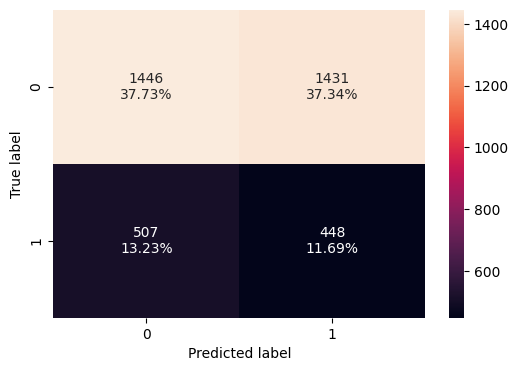

In [ ]:
# plotting the confusion matrix
draw_confusion_matrix(lr_rus, X_te, y_te)

- The model trained on undersampled data generalizes well to the test set

### Coefficient Interpretation

In [ ]:
# checking the model's coefficients and intercept (sklearn linear/logistic regression)

coefficients_df = pd.DataFrame(
    np.append(lr_rus.coef_, lr_rus.intercept_),
    index=X_tr.columns.tolist() + ["Intercept"],
    columns=["Coefficients"],
)
coefficients_df.T

,city_development_index,training_hours,city_Developing,city_Developed,gender_Male,gender_Other,relevent_experience_No relevent experience,enrolled_university_Part time course,enrolled_university_no_enrollment,education_level_High School,...,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never,Intercept
Coefficients,0.054352,-0.000887,0.103263,0.010653,0.011212,-0.005083,0.137695,-0.294376,-0.133099,0.099634,...,-0.002879,0.026705,-0.09013,0.077416,-0.019443,-0.193332,-0.206859,-0.159556,-0.180407,0.062606


* The coefficients of the logistic regression model are in terms of log(odd), to find the odds we have to take the exponential of the coefficients.
* Therefore, **odds =  exp(b)**
* The percentage change in odds is given as **odds = (exp(b) - 1) * 100**

In [ ]:
# turning the coefficients into odds
odds_values = np.exp(lr_rus.coef_[0])

# computing the percentage change in odds
odds_pct_change = (np.exp(lr_rus.coef_[0]) - 1) * 100

# lifting the cap on how many columns are displayed
pd.set_option("display.max_columns", None)

# storing the odds in a dataframe
odds_table = pd.DataFrame(
    {"Odds": odds_values, "Change_odd%": odds_pct_change}, index=X_tr.columns
).T

odds_table

,city_development_index,training_hours,city_Developing,city_Developed,gender_Male,gender_Other,relevent_experience_No relevent experience,enrolled_university_Part time course,enrolled_university_no_enrollment,education_level_High School,education_level_Masters,education_level_Phd,education_level_Primary School,major_discipline_Business Degree,major_discipline_Humanities,major_discipline_No Major,major_discipline_Other,major_discipline_STEM,experience_10,experience_11,experience_12,experience_13,experience_14,experience_15,experience_16,experience_17,experience_18,experience_19,experience_2,experience_20,experience_3,experience_4,experience_5,experience_6,experience_7,experience_8,experience_9,experience_<1,experience_>20,company_size_100-500,company_size_1000-4999,company_size_10000+,company_size_50-99,company_size_500-999,company_size_5000-9999,company_size_<10,company_type_Funded Startup,company_type_NGO,company_type_Other,company_type_Public Sector,company_type_Pvt Ltd,last_new_job_2,last_new_job_3,last_new_job_4,last_new_job_>4,last_new_job_never
Odds,1.055856,0.999114,1.108783,1.010710,1.011275,0.994930,1.147625,0.744997,0.875379,1.104767,1.029695,1.180049,1.106456,0.831844,1.090959,1.065076,0.969124,1.037763,1.299379,1.095390,1.111869,0.998746,0.906534,1.023396,1.208816,0.995129,1.190958,0.972154,0.968128,0.953633,0.831776,0.897296,1.150057,0.986455,0.946046,0.900698,0.920032,0.847785,1.061895,0.900953,1.081561,0.980049,0.888922,1.082084,1.108496,0.812703,1.349942,0.997125,1.027065,0.913813,1.080492,0.980745,0.824209,0.813135,0.852522,0.834931
Change_odd%,5.585599,-0.088632,10.878266,1.070952,1.127511,-0.506977,14.762507,-25.500344,-12.462135,10.476654,2.969523,18.004920,10.645554,-16.815619,9.095907,6.507558,-3.087560,3.776293,29.937874,9.538964,11.186908,-0.125427,-9.346583,2.339552,20.881618,-0.487090,19.095819,-2.784570,-3.187211,-4.636669,-16.822410,-10.270403,15.005655,-1.354517,-5.395434,-9.930187,-7.996795,-15.221493,6.189543,-9.904727,8.156059,-1.995111,-11.107828,8.208443,10.849586,-18.729699,34.994248,-0.287519,2.706478,-8.618737,8.049163,-1.925506,-17.579133,-18.686543,-14.747807,-16.506936


* `city_developement_index`: Keeping all other features constant, a 1 unit change in city_development_index raises the odds of a person looking for a job by ~1.05 times, i.e. a ~5.5% increase in the odds of looking for a job change

* `training_hours`: Keeping all other features constant, a 1 unit change in training_hours lowers the odds of a person looking for a job by ~0.99 times, i.e. a ~0.08% decrease in the odds of looking for a job change

* `city - developing/developed`:
    * A person from a developing city has ~1.10 times the odds of looking for a job change compared with a person from an under-developed city, i.e. ~10.7% higher odds. (under-developed cities are the reference).

    * Likewise, a person from a developed city has ~1.01 times the odds of looking for a job change compared with a person from an under-developed city, i.e. ~1.03% higher odds. (under-developed cities are the reference).

* `gender - male/other` -  A male has ~1.16% higher odds of looking for a job change than a female. Similarly, a person of 'other' gender has ~0.52% lower odds than a female. (females are the reference).

* `relevent_experience` - No relevant experience: A person with no relevant job experience has ~1.14 times the odds of looking for a job change compared with a person with some relevant experience, i.e. ~14.69% higher.


**Interpretation for other attributes can be made similarly.**

## Clean Feature Names (required for XGBoost and consistent modelling)

In [ ]:
def clean_col_names(df):
    """Replace characters that break XGBoost / sklearn and keep names unique."""
    new_names = []
    seen = {}
    for c in df.columns:
        name = (str(c)
                .replace("[", "").replace("]", "")
                .replace("<", "lt").replace(">", "gt")
                .replace(" ", "_").replace("/", "_")
                .replace("-", "_"))
        if name in seen:
            seen[name] += 1
            name = f"{name}_{seen[name]}"
        else:
            seen[name] = 0
        new_names.append(name)
    df = df.copy()
    df.columns = new_names
    return df

# Apply cleaning ONCE so every subsequent model sees the same columns
X_tr_smote = clean_col_names(X_tr_smote)
X_tr_rus   = clean_col_names(X_tr_rus)
X_tr       = clean_col_names(X_tr)
X_valid    = clean_col_names(X_valid)
X_te       = clean_col_names(X_te)

print("Any duplicate columns?", X_tr_smote.columns.duplicated().any())
print("Number of features:", X_tr_smote.shape[1])
print("Sample column names:", list(X_tr_smote.columns[:6]))

Any duplicate columns? False
Number of features: 56
Sample column names: ['city_development_index', 'training_hours', 'city_Developing', 'city_Developed', 'gender_Male', 'gender_Other']


**Pin-point observations**
- Column names that contained `<`, `>`, `-`, `/` or spaces have been sanitised.
- Uniqueness is guaranteed so XGBoost and all other models can run without name-mismatch errors.

## Ensemble Model Building

The logistic regression models above cover the Week-1 concepts.  
Below we add the ensemble techniques (Bagging, Boosting, Stacking) so that the workflow also includes the richer model suite present in a full modelling pipeline.  
All ensemble models are trained on the **SMOTE-balanced** training set; evaluation is performed on the held-out test set.

In [ ]:
def evaluate_clf(model, X_tr, y_tr, X_te, y_te, name="Model"):
    model.fit(X_tr, y_tr)
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)
    auc = roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]) if hasattr(model, "predict_proba") else np.nan
    return {
        "Model": name,
        "Train Acc": accuracy_score(y_tr, y_pred_tr),
        "Test Acc" : accuracy_score(y_te, y_pred_te),
        "Precision": precision_score(y_te, y_pred_te),
        "Recall"   : recall_score(y_te, y_pred_te),
        "F1"       : f1_score(y_te, y_pred_te),
        "ROC-AUC"  : auc
    }, model

### 1. Decision Tree (Baseline)

In [ ]:
dt = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dt_m, dt_f = evaluate_clf(dt, X_tr_smote, y_tr_smote, X_te, y_te, "Decision Tree")
pd.DataFrame([dt_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.998261,0.598904,0.245184,0.293194,0.267048,0.49642


### 2. Bagging Classifier

In [ ]:
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=1, class_weight="balanced"),
    n_estimators=50, random_state=1, n_jobs=-1
)
bag_m, bag_f = evaluate_clf(bag, X_tr_smote, y_tr_smote, X_te, y_te, "Bagging")
pd.DataFrame([bag_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Bagging,0.997914,0.66571,0.24127,0.159162,0.191798,0.49877


### 3. Random Forest – Hyper-parameter Tuning

In [ ]:
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=1, class_weight="balanced", n_jobs=-1),
    param_grid={"n_estimators": [100, 150], "max_depth": [10, 15], "min_samples_split": [2, 5]},
    cv=3, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_tr_smote, y_tr_smote)
print("Best RF params:", rf_grid.best_params_)

rf_m, rf_f = evaluate_clf(rf_grid.best_estimator_, X_tr_smote, y_tr_smote, X_te, y_te, "Random Forest (Tuned)")
pd.DataFrame([rf_m])

Best RF params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Random Forest (Tuned),0.851008,0.635177,0.256861,0.245026,0.250804,0.500465


### 4. AdaBoost

In [ ]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=3, random_state=1, class_weight="balanced"),
    n_estimators=50, learning_rate=0.1, random_state=1
)
ada_m, ada_f = evaluate_clf(ada, X_tr_smote, y_tr_smote, X_te, y_te, "AdaBoost")
pd.DataFrame([ada_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.655366,0.512787,0.246948,0.465969,0.322815,0.497662


### 5. Gradient Boosting – Hyper-parameter Tuning

In [ ]:
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=1),
    param_grid={"n_estimators": [100, 150], "learning_rate": [0.05, 0.1], "max_depth": [3, 4]},
    cv=3, scoring="f1", n_jobs=-1
)
gb_grid.fit(X_tr_smote, y_tr_smote)
print("Best GB params:", gb_grid.best_params_)

gb_m, gb_f = evaluate_clf(gb_grid.best_estimator_, X_tr_smote, y_tr_smote, X_te, y_te, "Gradient Boosting (Tuned)")
pd.DataFrame([gb_m])

Best GB params: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting (Tuned),0.763155,0.638831,0.255416,0.234555,0.244541,0.504228


### 6. XGBoost – Hyper-parameter Tuning

In [ ]:
xgb_grid = GridSearchCV(
    XGBClassifier(
        random_state=1,
        n_jobs=1,
        verbosity=0,
        eval_metric="logloss",
        use_label_encoder=False
    ),
    param_grid={
        "n_estimators": [100, 150],
        "learning_rate": [0.05, 0.1],
        "max_depth": [4, 5]
    },
    cv=3,
    scoring="f1",
    n_jobs=1,
    verbose=1
)
xgb_grid.fit(X_tr_smote, y_tr_smote)
print("Best XGB params:", xgb_grid.best_params_)

xgb_m, xgb_f = evaluate_clf(
    xgb_grid.best_estimator_,
    X_tr_smote, y_tr_smote,
    X_te, y_te,
    "XGBoost (Tuned)"
)
pd.DataFrame([xgb_m])

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best XGB params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}


,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,XGBoost (Tuned),0.787842,0.655532,0.259552,0.206283,0.229872,0.503447


### 7. Stacking Classifier

In [ ]:
estimators = [
    ("rf", RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=1, n_jobs=-1)),
    ("gb", GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=1)),
    ("xgb", XGBClassifier(n_estimators=100, max_depth=4, random_state=1, verbosity=0, eval_metric="logloss", use_label_encoder=False))
]
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(random_state=1, max_iter=500),
    n_jobs=-1
)
stack_m, stack_f = evaluate_clf(stack, X_tr_smote, y_tr_smote, X_te, y_te, "Stacking")
pd.DataFrame([stack_m])

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,Stacking,0.82806,0.677975,0.263158,0.162304,0.200777,0.495961


## Ensemble Model Comparison

In [ ]:
all_m = [dt_m, bag_m, rf_m, ada_m, gb_m, xgb_m, stack_m]
comp = pd.DataFrame(all_m).sort_values("F1", ascending=False).reset_index(drop=True)
comp

,Model,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
0,AdaBoost,0.655366,0.512787,0.246948,0.465969,0.322815,0.497662
1,Decision Tree,0.998261,0.598904,0.245184,0.293194,0.267048,0.496420
2,Random Forest (Tuned),0.851008,0.635177,0.256861,0.245026,0.250804,0.500465
3,Gradient Boosting (Tuned),0.763155,0.638831,0.255416,0.234555,0.244541,0.504228
4,XGBoost (Tuned),0.787842,0.655532,0.259552,0.206283,0.229872,0.503447
5,Stacking,0.828060,0.677975,0.263158,0.162304,0.200777,0.495961
6,Bagging,0.997914,0.665710,0.241270,0.159162,0.191798,0.498770


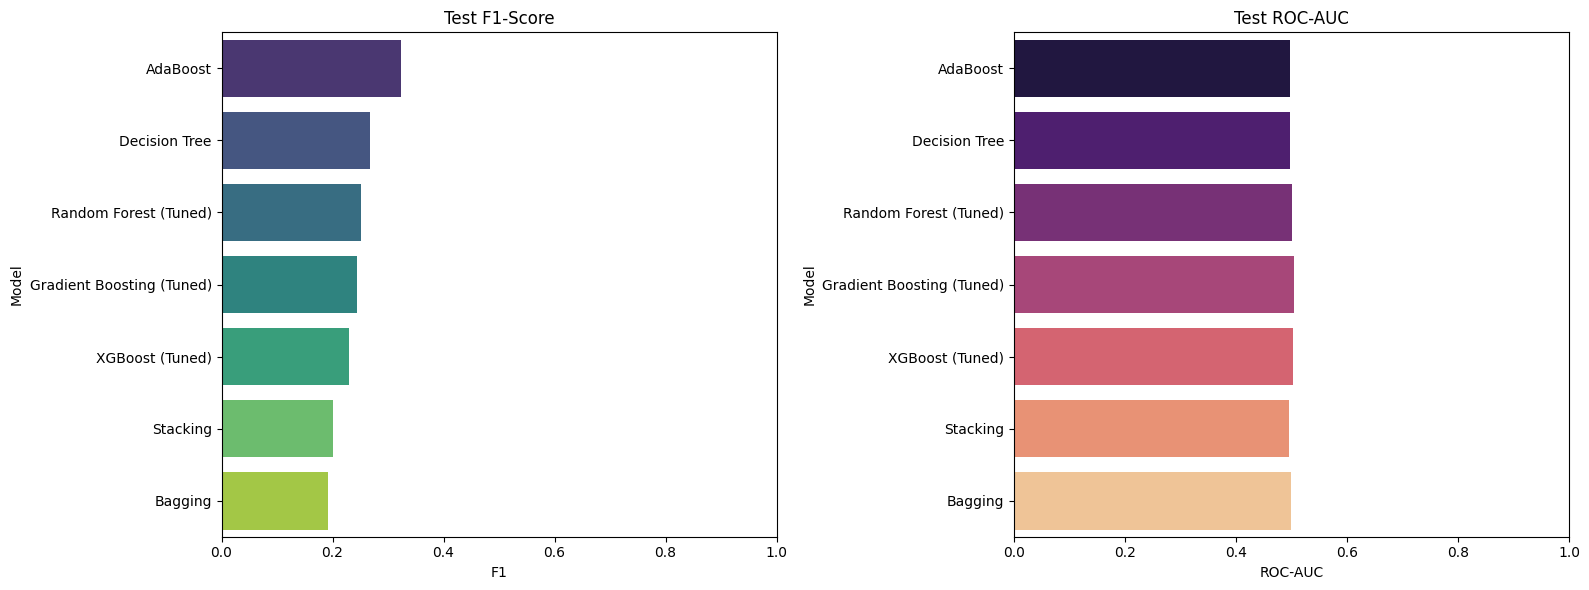

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x="F1", y="Model", data=comp, ax=ax[0], palette="viridis")
ax[0].set_title("Test F1-Score")
ax[0].set_xlim(0, 1)
sns.barplot(x="ROC-AUC", y="Model", data=comp, ax=ax[1], palette="magma")
ax[1].set_title("Test ROC-AUC")
ax[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

### Confusion Matrix & Classification Report (Best Ensemble Model)

              precision    recall  f1-score   support

 Not Looking       0.75      0.76      0.76      2877
     Looking       0.26      0.25      0.25       955

    accuracy                           0.64      3832
   macro avg       0.51      0.50      0.50      3832
weighted avg       0.63      0.64      0.63      3832



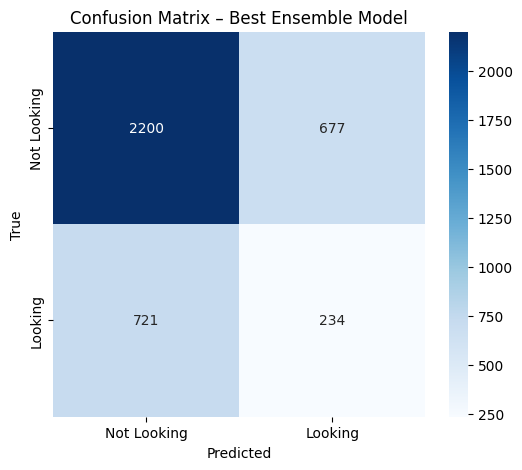

In [ ]:
best = rf_f   # swap if another model ranks higher on F1
y_pred = best.predict(X_te)
print(classification_report(y_te, y_pred, target_names=["Not Looking", "Looking"]))

cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Looking", "Looking"],
            yticklabels=["Not Looking", "Looking"])
plt.title("Confusion Matrix – Best Ensemble Model")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.show()

## Feature Importance (Ensemble)

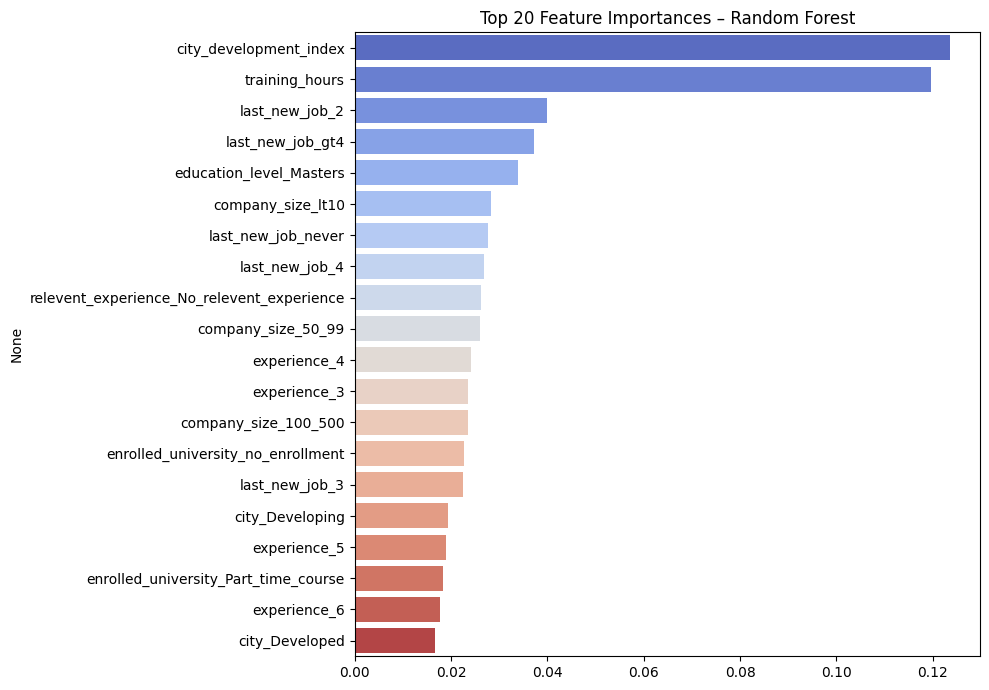

city_development_index                        0.123617
training_hours                                0.119706
last_new_job_2                                0.039958
last_new_job_gt4                              0.037134
education_level_Masters                       0.033991
company_size_lt10                             0.028224
last_new_job_never                            0.027634
last_new_job_4                                0.026813
relevent_experience_No_relevent_experience    0.026168
company_size_50_99                            0.026036
experience_4                                  0.024065
experience_3                                  0.023574
company_size_100_500                          0.023487
enrolled_university_no_enrollment             0.022669
last_new_job_3                                0.022491
city_Developing                               0.019272
experience_5                                  0.018890
enrolled_university_Part_time_course          0.018438
experience

In [ ]:
imp = pd.Series(rf_f.feature_importances_, index=X_tr_smote.columns).sort_values(ascending=False).head(20)
plt.figure(figsize=(10, 7))
sns.barplot(x=imp.values, y=imp.index, palette="coolwarm")
plt.title("Top 20 Feature Importances – Random Forest")
plt.tight_layout()
plt.show()
print(imp)

## Conclusions and Business Recommendations

* Both our analysis and the logistic regression model show that the number of training hours has very little effect on whether a person looks to change jobs, so the company should not give this attribute much weight when hiring.
* A person from an under-developed city is very likely to be looking for a switch, so an enrollee who meets the job-role criteria should be preferred over enrollees from other cities (developed and developing).
* To build a diverse culture, enrollees of other genders can be hired, as they are more likely to look for a new job role.
* Enrollees with no relevant experience or no experience at all - generally freshers - are more likely to look for a job, so those who meet the job criteria should be the company's focus.
* Enrollees from early-stage startups, the public sector or NGOs are more likely to move to a new role than those from the private sector or funded startups.
* Company size matters: enrollees who come from companies with many employees (1000-5000 or 10000+) are actively looking for a switch - they may now be seeking higher roles in team management, or they may find it easier to fit into a workplace given their broader exposure to a working environment.

#### **Note**: The aim of this case study is to cover the concepts of Week 1 in Model Tuning course. More predictive models and hyperparameter tuning can be tried to improve the results.